# Forecasting WAV service risk in New York City

**Research question:** How accurately can the borough-level share of completed WAV-requested HVFHV trips whose vehicle arrives more than 10 minutes after the requested pickup time be forecast one four-hour period ahead, using only information available beforehand?

# 1. Project setup and configuration

In [452]:
import sys
from pathlib import Path

In [453]:
PROJECT_ROOT = Path.cwd().resolve()

print(f"Project root: {PROJECT_ROOT}")
print(f"Python executable: {sys.executable}")

Project root: /Users/lavenderle/project-1-individual-LavenderLe7
Python executable: /Users/lavenderle/project-1-individual-LavenderLe7/.venv/bin/python


In [454]:
RANDOM_SEED = 42
TIMEZONE = "America/New_York"

ANALYSIS_YEAR = 2025
ANALYSIS_MONTHS = tuple(range(4, 13))

ANALYSIS_START = "2025-04-01 00:00:00"
TRAIN_END_EXCLUSIVE = "2025-09-01 00:00:00"
VALIDATION_END_EXCLUSIVE = "2025-11-01 00:00:00"
ANALYSIS_END_EXCLUSIVE = "2026-01-01 00:00:00"
TEST_END_EXCLUSIVE = ANALYSIS_END_EXCLUSIVE

PERIOD_HOURS = 4
FORECAST_HORIZON_PERIODS = 1
LATE_THRESHOLD_MINUTES = 10
WAV_REQUEST_FLAG_VALUE = "Y"

NYC_BOROUGHS = (
    "Bronx",
    "Brooklyn",
    "Manhattan",
    "Queens",
    "Staten Island",
)

In [455]:
# Input data roots
RAW_DATA_ROOT = PROJECT_ROOT / "data" / "raw"
REFERENCE_DATA_ROOT = PROJECT_ROOT / "data" / "reference"

# Pipeline-generated data roots
STANDARDIZED_DATA_ROOT = PROJECT_ROOT / "data" / "standardized"
CURATED_DATA_ROOT = PROJECT_ROOT / "data" / "curated"

In [456]:
# Processed data outputs
STANDARDIZED_WAV_REQUEST_ROOT = STANDARDIZED_DATA_ROOT / "wav_requests"
CURATED_WAV_PANEL_PATH = (
    CURATED_DATA_ROOT
    / "wav_service_risk"
    / "borough_four_hour_panel.parquet"
)

# Report and model outputs
OUTPUT_ROOT = PROJECT_ROOT / "outputs"
FIGURE_OUTPUT_ROOT = OUTPUT_ROOT / "figures"
TABLE_OUTPUT_ROOT = OUTPUT_ROOT / "tables"
MODEL_OUTPUT_ROOT = OUTPUT_ROOT / "model_results"

In [457]:
# Create required output directories
required_output_directories = (
    STANDARDIZED_WAV_REQUEST_ROOT.parent,
    CURATED_WAV_PANEL_PATH.parent,
    FIGURE_OUTPUT_ROOT,
    TABLE_OUTPUT_ROOT,
    MODEL_OUTPUT_ROOT,
)

for output_directory in required_output_directories:
    output_directory.mkdir(parents=True, exist_ok=True)

In [458]:
print(f"Analysis period: [{ANALYSIS_START}, {ANALYSIS_END_EXCLUSIVE})")
print(f"Training: [{ANALYSIS_START}, {TRAIN_END_EXCLUSIVE})")
print(
    f"Validation: [{TRAIN_END_EXCLUSIVE}, "
    f"{VALIDATION_END_EXCLUSIVE})"
)
print(
    f"Final test: [{VALIDATION_END_EXCLUSIVE}, "
    f"{TEST_END_EXCLUSIVE})"
)
print(f"Forecast period: {PERIOD_HOURS} hours")
print(f"Late-arrival threshold: {LATE_THRESHOLD_MINUTES} minutes")

Analysis period: [2025-04-01 00:00:00, 2026-01-01 00:00:00)
Training: [2025-04-01 00:00:00, 2025-09-01 00:00:00)
Validation: [2025-09-01 00:00:00, 2025-11-01 00:00:00)
Final test: [2025-11-01 00:00:00, 2026-01-01 00:00:00)
Forecast period: 4 hours
Late-arrival threshold: 10 minutes


# 2. Imports and Spark session

In [459]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import seaborn as sns
import statsmodels.api as sm
from pyspark import StorageLevel
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql import types as T
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

In [460]:
np.random.seed(RANDOM_SEED)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid", context="notebook")

In [461]:
SPARK_APP_NAME = "MAST30034_Assignment1"
SPARK_DRIVER_MEMORY = "4g"
SPARK_SHUFFLE_PARTITIONS = 16

# Initialise and configure the local Spark session
spark = (
    SparkSession.builder
    .appName(SPARK_APP_NAME)
    .master("local[*]")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.driver.memory", SPARK_DRIVER_MEMORY)
    .config("spark.ui.showConsoleProgress", "false")
    .config("spark.sql.shuffle.partitions", SPARK_SHUFFLE_PARTITIONS)
    .config("spark.sql.session.timeZone", TIMEZONE)
    .config("spark.sql.parquet.compression.codec", "zstd")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

In [462]:
print(
    f"Spark name: {spark.sparkContext.appName}, "
    f"Spark ready: {spark.sparkContext.master}, "
    f"timezone {spark.conf.get("spark.sql.session.timeZone")}"
)

Spark name: MAST30034_Assignment1, Spark ready: local[*], timezone America/New_York


# 3. Load and summarise source data

## 3.1 HVFHV trip records

Report the scale of the April–December source data and load only the fields needed to define completed WAV-requested trips and their arrival outcome.

In [463]:
# Fixed HVFHV inputs for the study period
HVFHV_TRIP_ROOT = (
    RAW_DATA_ROOT / "tlc" / "trips" / "hvfhv" / str(ANALYSIS_YEAR)
)
EXPECTED_HVFHV_FILENAMES = tuple(
    f"fhvhv_tripdata_{ANALYSIS_YEAR}-{month:02d}.parquet"
    for month in ANALYSIS_MONTHS
)
EXPECTED_HVFHV_PATHS = tuple(
    HVFHV_TRIP_ROOT / file_name
    for file_name in EXPECTED_HVFHV_FILENAMES
)

# Fields required to define the WAV population and outcome
REQUIRED_HVFHV_COLUMNS = (
    "request_datetime",
    "on_scene_datetime",
    "pickup_datetime",
    "PULocationID",
    "wav_request_flag",
)

In [464]:
raw_row_count_from_metadata = sum(
    pq.ParquetFile(source_path).metadata.num_rows
    for source_path in EXPECTED_HVFHV_PATHS
)
raw_source_size_gb = (
    sum(source_path.stat().st_size for source_path in EXPECTED_HVFHV_PATHS)
    / 1024**3
)

print(
    f"Raw HVFHV source: {len(EXPECTED_HVFHV_PATHS)} monthly files, "
    f"{raw_row_count_from_metadata:,} rows, "
    f"{raw_source_size_gb:.2f} GiB"
)

Raw HVFHV source: 9 monthly files, 183,307,678 rows, 4.20 GiB


`request_datetime` anchors the four-hour target period, while `on_scene_datetime` defines vehicle arrival. `pickup_datetime` confirms a completed trip, `PULocationID` supplies pickup geography, and `wav_request_flag` identifies WAV-requested trips.

In [465]:
raw_hvfhv_df = (
    spark.read
    .parquet(*[str(path) for path in EXPECTED_HVFHV_PATHS])
    .select(*REQUIRED_HVFHV_COLUMNS)
)

## 3.2 Pickup geography

Join the TLC Taxi Zone lookup so each trip can be assigned to one of the five pickup boroughs.

In [466]:
TAXI_ZONE_LOOKUP_PATH = RAW_DATA_ROOT / "tlc" / "geography" / "taxi_zone_lookup.csv"

TAXI_ZONE_LOOKUP_SCHEMA = T.StructType(
    [
        T.StructField("LocationID", T.IntegerType(), False),
        T.StructField("Borough", T.StringType(), True),
        T.StructField("Zone", T.StringType(), True),
        T.StructField("service_zone", T.StringType(), True),
    ]
)

taxi_zone_lookup_df = (
    spark.read
    .option("header", True)
    .schema(TAXI_ZONE_LOOKUP_SCHEMA)
    .csv(str(TAXI_ZONE_LOOKUP_PATH))
    .select(
        F.col("LocationID").alias("pickup_location_id"),
        F.col("Zone").alias("pickup_zone"),
        F.col("Borough").alias("pickup_borough"),
    )
)

In [467]:
raw_hvfhv_profile_df = (
    raw_hvfhv_df
    .join(
        F.broadcast(taxi_zone_lookup_df),
        F.col("PULocationID") == F.col("pickup_location_id"),
        how="left",
    )
    .drop("pickup_location_id")
    .withColumn(
        "valid_nyc_pickup_zone",
        F.col("pickup_borough").isin(*NYC_BOROUGHS),
    )
)

# 4. Define the WAV analysis population and target

## 4.1 WAV population definition

In [468]:
# Identify WAV-requested trips
is_wav_requested = (F.upper(F.trim(F.col("wav_request_flag"))) == WAV_REQUEST_FLAG_VALUE)

# Require complete timestamps for completed-trip outcome construction
has_completed_trip_timestamps = (
    F.col("request_datetime").isNotNull()
    & F.col("on_scene_datetime").isNotNull()
    & F.col("pickup_datetime").isNotNull()
)

# Restrict trips to the fixed analysis interval
is_in_analysis_interval = (
    (F.col("request_datetime") >= F.lit(ANALYSIS_START))
    & (F.col("request_datetime") < F.lit(ANALYSIS_END_EXCLUSIVE))
)

# Require a valid NYC pickup zone
has_valid_nyc_pickup = F.coalesce(F.col("valid_nyc_pickup_zone"),F.lit(False),)

# Combine eligibility conditions for the WAV analysis population
valid_wav_population = (
    is_wav_requested
    & has_completed_trip_timestamps
    & is_in_analysis_interval
    & has_valid_nyc_pickup
)

In [469]:
# Define cumulative filtering stages for the WAV analysis population
filter_stage_definitions = (
    ("Raw HVFHV records", F.lit(True)),
    ("Passenger requested a WAV", is_wav_requested),
    ("Required trip timestamps present", is_wav_requested & has_completed_trip_timestamps,),
    (
        "Requested pickup inside study interval",
        is_wav_requested
        & has_completed_trip_timestamps
        & is_in_analysis_interval,
    ),
    ("Valid five-borough pickup zone", valid_wav_population),
)

# Count records retained at all filtering stages in a single Spark aggregation
filter_count_record = (
    raw_hvfhv_profile_df
    .agg(
        *(
            F.sum(condition.cast("long")).alias(f"stage_{index}")
            for index, (_, condition) in enumerate(
                filter_stage_definitions
            )
        )
    )
    .first()
    .asDict()
)

# Summarise stage-specific exclusions and retention relative to the raw data
filtering_summary_records = []
previous_row_count = None
raw_filter_row_count = filter_count_record["stage_0"]

for stage_order, (stage_name, _) in enumerate(filter_stage_definitions):
    stage_row_count = filter_count_record[f"stage_{stage_order}"]
    excluded_row_count = (0 if previous_row_count is None else previous_row_count - stage_row_count)
    filtering_summary_records.append(
        {
            "stage": stage_name,
            "row_count": stage_row_count,
            "excluded_at_stage": excluded_row_count,
            "retained_percentage_of_raw": (100 * stage_row_count / raw_filter_row_count),
        }
    )
    previous_row_count = stage_row_count

wav_filtering_summary_df = pd.DataFrame(filtering_summary_records)
display(wav_filtering_summary_df)

wav_population_df = raw_hvfhv_profile_df.filter(valid_wav_population)

,stage,row_count,excluded_at_stage,retained_percentage_of_raw
0,Raw HVFHV records,183307678,0,100.0000
1,Passenger requested a WAV,543349,182764329,0.2964
2,Required trip timestamps present,543349,0,0.2964
3,Requested pickup inside study interval,543347,2,0.2964
4,Valid five-borough pickup zone,543305,42,0.2964


## 4.2 Timestamp interpretation and target construction

In [470]:
# Calculate vehicle arrival offset from the requested pickup time
arrival_offset_minutes = (
    F.timestamp_diff(
        "SECOND",
        "request_datetime",
        "on_scene_datetime",
    )
    / F.lit(60.0)
)

# Assign each request to the start of its fixed-length time period
period_start_hour = (F.floor(F.hour("request_datetime") / F.lit(PERIOD_HOURS)) * F.lit(PERIOD_HOURS)).cast("int")
period_start = F.make_timestamp_ntz(
    years=F.year("request_datetime"),
    months=F.month("request_datetime"),
    days=F.dayofmonth("request_datetime"),
    hours=period_start_hour,
    mins=F.lit(0),
    secs=F.lit(0),
)

In [471]:
# Construct trip-level outcome and temporal variables for WAV analysis
wav_target_df = (
    wav_population_df
    .withColumn("arrival_offset_minutes", arrival_offset_minutes)
    .withColumn(
        "late_10",
        (F.col("arrival_offset_minutes") > F.lit(LATE_THRESHOLD_MINUTES)).cast("int"),
    )
    .withColumn("requested_pickup_date", F.to_date("request_datetime"))
    .withColumn("period_start", period_start)
    .withColumn("year", F.year("request_datetime"))
    .withColumn("month", F.month("request_datetime"))
    .persist(StorageLevel.MEMORY_AND_DISK)
)

## 4.3 Arrival-offset distribution

In [472]:
# Calculate basic summary statistics for vehicle arrival offsets
offset_summary = (
    wav_target_df
    .agg(
        F.count("*").alias("record_count"),
        F.min("arrival_offset_minutes").alias("minimum_minutes"),
        F.max("arrival_offset_minutes").alias("maximum_minutes"),
        F.sum(
            (F.col("arrival_offset_minutes") < 0).cast("long")
        ).alias("negative_count"),
        F.sum("late_10").alias("late_10_count"),
    )
    .first()
    .asDict()
)

# Calculate selected quantiles of the arrival-offset distribution
OFFSET_QUANTILE_PROBABILITIES = (0.01, 0.50, 0.95, 0.99)
OFFSET_QUANTILE_NAMES = (
    "p01_minutes",
    "median_minutes",
    "p95_minutes",
    "p99_minutes",
)
offset_quantiles = wav_target_df.approxQuantile(
    "arrival_offset_minutes",
    list(OFFSET_QUANTILE_PROBABILITIES),
    0.0001,
)

# Combine counts, quantiles, and percentages into one summary table
offset_profile_record = {
    **offset_summary,
    **dict(zip(OFFSET_QUANTILE_NAMES, offset_quantiles, strict=True)),
    "negative_percentage": (
        100
        * offset_summary["negative_count"]
        / offset_summary["record_count"]
    ),
    "late_10_percentage": (
        100
        * offset_summary["late_10_count"]
        / offset_summary["record_count"]
    ),
}

wav_arrival_offset_profile_df = pd.DataFrame([offset_profile_record])
wav_arrival_offset_profile_df.T.rename(columns={0: "value"})

,value
record_count,543305.0000
minimum_minutes,-69.0333
maximum_minutes,212.4000
negative_count,109401.0000
late_10_count,47450.0000
p01_minutes,-16.1167
median_minutes,4.1833
p95_minutes,11.9167
p99_minutes,18.3000
negative_percentage,20.1362


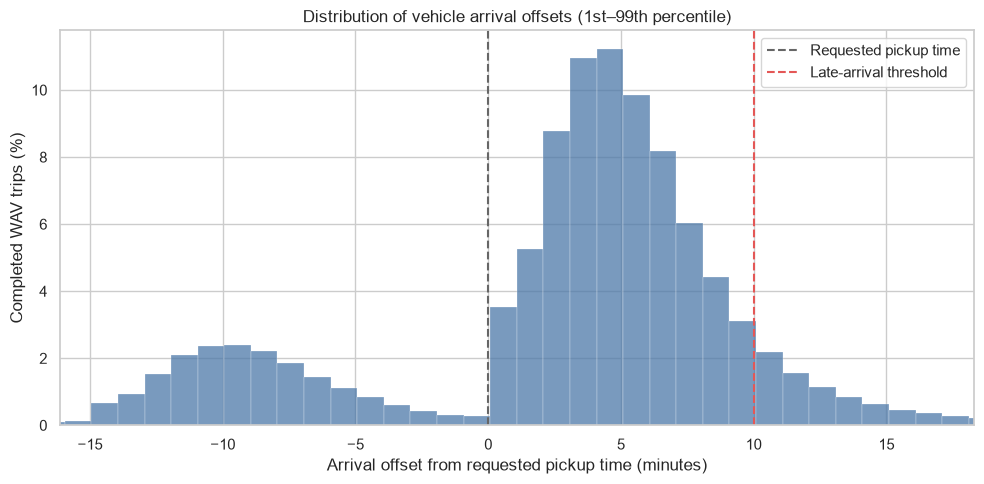

In [473]:
# Visualise the central arrival-offset distribution
arrival_offset_plot_df = (
    wav_target_df
    .select("arrival_offset_minutes")
    .toPandas()
)

figure, axis = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=arrival_offset_plot_df,
    x="arrival_offset_minutes",
    binwidth=1,
    stat="percent",
    color="#4C78A8",
    ax=axis,
)

axis.axvline(
    0,
    color="#666666",
    linestyle="--",
    linewidth=1.5,
    label="Requested pickup time",
)

axis.axvline(
    LATE_THRESHOLD_MINUTES,
    color="#E45756",
    linestyle="--",
    linewidth=1.5,
    label="Late-arrival threshold",
)

axis.set_xlim(
    offset_profile_record["p01_minutes"],
    offset_profile_record["p99_minutes"],
)

axis.set_xlabel(
    "Arrival offset from requested pickup time (minutes)"
)
axis.set_ylabel("Completed WAV trips (%)")
axis.set_title(
    "Distribution of vehicle arrival offsets "
    "(1st–99th percentile)"
)
axis.legend()

figure.tight_layout()
plt.show()


## 4.4 Standardised WAV trip output

In [ ]:
STANDARDIZED_WAV_SCHEMA = {
    "requested_pickup_datetime": "timestamp_ntz",
    "on_scene_datetime": "timestamp_ntz",
    "pickup_datetime": "timestamp_ntz",
    "pickup_location_id": "int",
    "pickup_zone": "string",
    "pickup_borough": "string",
    "arrival_offset_minutes": "double",
    "late_10": "int",
    "period_start": "timestamp_ntz",
    "month": "int",
}

In [558]:
# Create and save the standardized trip-level WAV dataset
wav_standardized_df = wav_target_df.select(
    F.col("request_datetime").alias("requested_pickup_datetime"),
    "on_scene_datetime",
    "pickup_datetime",
    F.col("PULocationID").alias("pickup_location_id"),
    "pickup_zone",
    "pickup_borough",
    "arrival_offset_minutes",
    "late_10",
    "period_start",
    "month",
)

(
    wav_standardized_df
    .repartition(len(ANALYSIS_MONTHS), "month")
    .write
    .mode("overwrite")
    .partitionBy("month")
    .parquet(str(STANDARDIZED_WAV_REQUEST_ROOT))
)

wav_target_df.unpersist()

print(
    f"Saved standardised WAV trips to "
    f"{STANDARDIZED_WAV_REQUEST_ROOT}"
)

Saved standardised WAV trips to /Users/lavenderle/project-1-individual-LavenderLe7/data/standardized/wav_requests


# 5. External data and modelling panel

## 5.1 Taxi Zone and borough geography

In [ ]:
TAXI_ZONE_SHAPEFILE_PATH = (
    RAW_DATA_ROOT
    / "tlc"
    / "geography"
    / "taxi_zones"
    / "taxi_zones"
    / "taxi_zones.shp"
)

taxi_zone_lookup_pandas_df = pd.read_csv(TAXI_ZONE_LOOKUP_PATH)
taxi_zone_shapes_gdf = gpd.read_file(TAXI_ZONE_SHAPEFILE_PATH)

taxi_zones_gdf = (
    taxi_zone_shapes_gdf
    .drop(columns=["zone", "borough"], errors="ignore")
    .merge(
        taxi_zone_lookup_pandas_df,
        on="LocationID",
        how="left",
        validate="one_to_one",
    )
    .rename(
        columns={
            "LocationID": "pickup_location_id",
            "Zone": "pickup_zone",
            "Borough": "pickup_borough",
        }
    )
)

print(f"Taxi Zone geometries: {len(taxi_zones_gdf):,}")
print(f"Taxi Zone CRS: {taxi_zones_gdf.crs}")

Taxi Zone geometries: 263
Taxi Zone CRS: EPSG:2263


## 5.2 NOAA weather processing

Parse Central Park LCD observations, align fixed standard time with New York civil time, aggregate multiple reports to one record per hour, and preserve weather coverage.

In [479]:
NOAA_FIXED_STANDARD_TIMEZONE = "Etc/GMT+5"
NOAA_WEATHER_COLUMNS = (
    "STATION",
    "DATE",
    "REPORT_TYPE",
    "HourlyDryBulbTemperature",
    "HourlyPrecipitation",
    "HourlyWindSpeed",
    "HourlyVisibility",
    "HourlyPresentWeatherType",
)


def parse_noaa_numeric(values: pd.Series) -> pd.Series:
    """
    Convert NOAA numeric strings to floats while removing quality suffixes.
    """
    extracted_values = (
        values
        .astype("string")
        .str.extract(r"([-+]?\d+(?:\.\d+)?)", expand=False)
    )
    return pd.to_numeric(extracted_values, errors="coerce")


def parse_noaa_precipitation(values: pd.Series) -> pd.DataFrame:
    """
    Parse precipitation amounts and retain a separate trace indicator.
    """
    cleaned_values = values.astype("string").str.strip().str.upper()
    return pd.DataFrame(
        {
            "precipitation_mm": parse_noaa_numeric(cleaned_values),
            "is_trace_precipitation": cleaned_values.eq("T"),
        },
        index=values.index,
    )

In [480]:
NOAA_STATION_ID = "USW00094728"
NOAA_WEATHER_PATH = (
    RAW_DATA_ROOT
    / "external"
    / "noaa_weather"
    / f"LCD_{NOAA_STATION_ID}_{ANALYSIS_YEAR}.csv"
)

weather_raw_df = pd.read_csv(
    NOAA_WEATHER_PATH,
    usecols=NOAA_WEATHER_COLUMNS,
    dtype="string",
)

observed_station_ids = set(weather_raw_df["STATION"].dropna().unique())
if observed_station_ids != {NOAA_STATION_ID}:
    raise ValueError(
        f"Unexpected NOAA station IDs: {sorted(observed_station_ids)}"
    )

weather_source_datetime = pd.to_datetime(
    weather_raw_df["DATE"],
    errors="coerce",
)
weather_raw_df["observation_datetime"] = (
    weather_source_datetime
    .dt.tz_localize(NOAA_FIXED_STANDARD_TIMEZONE)
    .dt.tz_convert(TIMEZONE)
    .dt.tz_localize(None)
)

if weather_raw_df["observation_datetime"].isna().any():
    raise ValueError("NOAA contains unparseable observation timestamps.")

In [481]:
precipitation_fields_df = parse_noaa_precipitation(
    weather_raw_df["HourlyPrecipitation"]
)
weather_codes = (
    weather_raw_df["HourlyPresentWeatherType"]
    .fillna("")
    .str.upper()
)

weather_raw_df = weather_raw_df.assign(
    temperature_c=parse_noaa_numeric(
        weather_raw_df["HourlyDryBulbTemperature"]
    ),
    precipitation_mm=precipitation_fields_df["precipitation_mm"],
    is_trace_precipitation=(
        precipitation_fields_df["is_trace_precipitation"]
    ),
    wind_speed_ms=parse_noaa_numeric(
        weather_raw_df["HourlyWindSpeed"]
    ),
    visibility_km=parse_noaa_numeric(
        weather_raw_df["HourlyVisibility"]
    ),
)
weather_raw_df["is_rain"] = (
    weather_raw_df["is_trace_precipitation"]
    | weather_raw_df["precipitation_mm"].gt(0)
    | weather_codes.str.contains(
        r"(?:RA|DZ|SHRA|TSRA)",
        regex=True,
    )
).fillna(False)
weather_raw_df["is_snow"] = weather_codes.str.contains(
    r"(?:SN|SG|PL|IC)",
    regex=True,
)

In [482]:
weather_raw_df["observation_hour"] = (
    weather_raw_df["observation_datetime"].dt.floor("h")
)
weather_hourly_df = (
    weather_raw_df
    .groupby("observation_hour", as_index=True)
    .agg(
        temperature_c=("temperature_c", "median"),
        precipitation_mm=("precipitation_mm", "max"),
        wind_speed_ms=("wind_speed_ms", "max"),
        visibility_km=("visibility_km", "min"),
        is_rain=("is_rain", "max"),
        is_snow=("is_snow", "max"),
        observation_count=("REPORT_TYPE", "size"),
    )
)

expected_weather_hours = pd.date_range(
    start=ANALYSIS_START,
    end=ANALYSIS_END_EXCLUSIVE,
    inclusive="left",
    freq="h",
)
weather_hourly_df = weather_hourly_df.reindex(expected_weather_hours)
weather_hourly_df.index.name = "observation_hour"
weather_hourly_df["weather_observed"] = (
    weather_hourly_df["observation_count"].fillna(0).gt(0)
)
weather_hourly_df.loc[
    weather_hourly_df["weather_observed"]
    & weather_hourly_df["precipitation_mm"].isna(),
    "precipitation_mm",
] = 0.0

In [483]:
weather_hourly_for_period_df = weather_hourly_df.reset_index()
weather_hourly_for_period_df["period_start"] = (
    weather_hourly_for_period_df["observation_hour"].dt.floor("4h")
)
weather_period_df = (
    weather_hourly_for_period_df
    .groupby("period_start", as_index=False)
    .agg(
        observed_mean_temperature_c=("temperature_c", "mean"),
        observed_total_precipitation_mm=(
            "precipitation_mm",
            lambda values: values.sum(min_count=1),
        ),
        observed_max_wind_speed_ms=("wind_speed_ms", "max"),
        observed_min_visibility_km=("visibility_km", "min"),
        observed_any_rain=("is_rain", "max"),
        observed_any_snow=("is_snow", "max"),
        weather_observation_count=("weather_observed", "sum"),
    )
)
weather_period_df["weather_coverage_share"] = (
    weather_period_df["weather_observation_count"] / PERIOD_HOURS
)

weather_quality_summary_df = pd.DataFrame(
    [
        {
            "expected_hour_count": len(expected_weather_hours),
            "observed_hour_count": int(
                weather_hourly_df["weather_observed"].sum()
            ),
            "hourly_coverage_percentage": (
                100 * weather_hourly_df["weather_observed"].mean()
            ),
            "complete_period_count": int(
                weather_period_df["weather_coverage_share"].eq(1).sum()
            ),
            "period_count": len(weather_period_df),
        }
    ]
)
weather_quality_summary_df

,expected_hour_count,observed_hour_count,hourly_coverage_percentage,complete_period_count,period_count
0,6600,6489,98.3182,1607,1650


In [484]:
WEATHER_PERIOD_SCHEMA = T.StructType(
    [
        T.StructField("period_start", T.TimestampNTZType(), False),
        T.StructField("observed_mean_temperature_c", T.DoubleType()),
        T.StructField("observed_total_precipitation_mm", T.DoubleType()),
        T.StructField("observed_max_wind_speed_ms", T.DoubleType()),
        T.StructField("observed_min_visibility_km", T.DoubleType()),
        T.StructField("observed_any_rain", T.BooleanType()),
        T.StructField("observed_any_snow", T.BooleanType()),
        T.StructField("weather_observation_count", T.LongType()),
        T.StructField("weather_coverage_share", T.DoubleType()),
    ]
)
weather_period_records = []
for weather_record in weather_period_df.to_dict(orient="records"):
    cleaned_weather_record = {
        field_name: (
            None
            if pd.isna(field_value)
            else (
                field_value.item()
                if isinstance(field_value, np.generic)
                else field_value
            )
        )
        for field_name, field_value in weather_record.items()
    }
    cleaned_weather_record["period_start"] = weather_record[
        "period_start"
    ].to_pydatetime()
    weather_period_records.append(cleaned_weather_record)

weather_period_spark_df = spark.createDataFrame(
    weather_period_records,
    schema=WEATHER_PERIOD_SCHEMA,
)

## 5.3 Holiday and deterministic calendar features

Create the federal-holiday indicator and deterministic calendar features available before each target period.

In [485]:
HOLIDAY_CALENDAR_PATH = REFERENCE_DATA_ROOT / "holiday_calendar.csv"

holiday_reference_df = pd.read_csv(
    HOLIDAY_CALENDAR_PATH,
    parse_dates=["date"],
)
nyc_holiday_dates = tuple(
    holiday_reference_df.loc[
        holiday_reference_df["applies_to_nyc"].eq(1),
        "date",
    ]
    .dt.strftime("%Y-%m-%d")
    .tolist()
)

if not nyc_holiday_dates:
    raise ValueError("Holiday reference contains no NYC-applicable dates.")

## 5.4 Complete borough-period grid and target aggregation

Create every borough × four-hour combination, retain zero-request periods, and aggregate completed WAV requests and late outcomes onto the complete grid.

In [486]:
period_start_values = pd.date_range(
    start=ANALYSIS_START,
    end=ANALYSIS_END_EXCLUSIVE,
    inclusive="left",
    freq=f"{PERIOD_HOURS}h",
).to_pydatetime()

period_grid_schema = T.StructType(
    [T.StructField("period_start", T.TimestampNTZType(), False)]
)
borough_grid_schema = T.StructType(
    [T.StructField("borough", T.StringType(), False)]
)
period_grid_df = spark.createDataFrame(
    [(value,) for value in period_start_values],
    schema=period_grid_schema,
)
borough_grid_df = spark.createDataFrame(
    [(borough,) for borough in NYC_BOROUGHS],
    schema=borough_grid_schema,
)
complete_borough_period_grid_df = borough_grid_df.crossJoin(period_grid_df)

EXPECTED_PERIOD_COUNT = len(period_start_values)
EXPECTED_PANEL_ROW_COUNT = EXPECTED_PERIOD_COUNT * len(NYC_BOROUGHS)
actual_grid_row_count = complete_borough_period_grid_df.count()

if actual_grid_row_count != EXPECTED_PANEL_ROW_COUNT:
    raise RuntimeError(
        f"Complete grid has {actual_grid_row_count:,} rows; "
        f"expected {EXPECTED_PANEL_ROW_COUNT:,}."
    )

print(
    f"Complete grid: {EXPECTED_PERIOD_COUNT:,} periods × "
    f"{len(NYC_BOROUGHS)} boroughs = {actual_grid_row_count:,} rows"
)

Complete grid: 1,650 periods × 5 boroughs = 8,250 rows


In [487]:
day_of_week_number = F.pmod(
    F.dayofweek("period_start") + F.lit(5),
    F.lit(7),
)
time_block_end_hour = F.hour("period_start") + F.lit(PERIOD_HOURS - 1)

calendar_grid_df = (
    complete_borough_period_grid_df
    .withColumn("hour_start", F.hour("period_start"))
    .withColumn(
        "time_block",
        F.concat(
            F.lpad(F.col("hour_start").cast("string"), 2, "0"),
            F.lit(":00-"),
            F.lpad(time_block_end_hour.cast("string"), 2, "0"),
            F.lit(":59"),
        ),
    )
    .withColumn("day_of_week", F.date_format("period_start", "EEEE"))
    .withColumn("day_of_week_number", day_of_week_number.cast("int"))
    .withColumn("day_of_year", F.dayofyear("period_start"))
    .withColumn(
        "day_of_year_sin",
        F.sin(
            2 * F.lit(np.pi)
            * (F.col("day_of_year") - F.lit(1))
            / F.lit(365.25)
        ),
    )
    .withColumn(
        "day_of_year_cos",
        F.cos(
            2 * F.lit(np.pi)
            * (F.col("day_of_year") - F.lit(1))
            / F.lit(365.25)
        ),
    )
    .withColumn(
        "days_since_analysis_start",
        F.datediff("period_start", F.lit(ANALYSIS_START)),
    )
    .withColumn(
        "is_holiday",
        F.date_format("period_start", "yyyy-MM-dd").isin(
            *nyc_holiday_dates
        ),
    )
    .withColumn(
        "split_label",
        F.when(
            F.col("period_start") < F.lit(TRAIN_END_EXCLUSIVE),
            F.lit("training"),
        )
        .when(
            F.col("period_start") < F.lit(VALIDATION_END_EXCLUSIVE),
            F.lit("validation"),
        )
        .otherwise(F.lit("test")),
    )
)

In [488]:
standardized_wav_requests_df = spark.read.parquet(
    str(STANDARDIZED_WAV_REQUEST_ROOT)
)
wav_period_counts_df = (
    standardized_wav_requests_df
    .groupBy(
        F.col("pickup_borough").alias("borough"),
        "period_start",
    )
    .agg(
        F.count("*").alias("wav_request_count"),
        F.sum("late_10").alias("late_trip_count"),
    )
)

In [489]:
wav_panel_df = (
    calendar_grid_df
    .join(
        wav_period_counts_df,
        on=["borough", "period_start"],
        how="left",
    )
    .fillna(0, subset=["wav_request_count", "late_trip_count"])
    .withColumn(
        "target_observed",
        F.col("wav_request_count") > 0,
    )
    .withColumn(
        "late_share",
        F.when(
            F.col("target_observed"),
            F.col("late_trip_count") / F.col("wav_request_count"),
        ),
    )
)

In [490]:
target_reconciliation = (
    wav_panel_df
    .agg(
        F.count("*").alias("panel_row_count"),
        F.sum("wav_request_count").alias("wav_request_count"),
        F.sum("late_trip_count").alias("late_trip_count"),
    )
    .first()
    .asDict()
)

target_reconciliation

{'panel_row_count': 8250,
 'wav_request_count': 543305,
 'late_trip_count': 47450}

In [491]:
citywide_wav_counts_df = (
    wav_period_counts_df
    .groupBy("period_start")
    .agg(
        F.sum("wav_request_count").alias(
            "citywide_wav_request_count"
        )
    )
)

panel_source_df = (
    wav_panel_df
    .join(citywide_wav_counts_df, on="period_start", how="left")
    .join(weather_period_spark_df, on="period_start", how="left")
    .fillna(0, subset=["citywide_wav_request_count"])
)

In [492]:
join_audit_record = (
    panel_source_df
    .agg(
        F.count("*").alias("panel_row_count"),
        F.sum(
            F.col("target_observed").cast("long")
        ).alias("target_observed_rows"),
        F.sum(
            (F.col("weather_coverage_share") > 0).cast("long")
        ).alias("weather_observed_rows"),
    )
    .first()
    .asDict()
)
if join_audit_record["panel_row_count"] != EXPECTED_PANEL_ROW_COUNT:
    raise RuntimeError("External joins changed the complete panel shape.")

wav_external_join_summary_df = pd.DataFrame(
    [
        {
            "source": "WAV target",
            "matched_rows": join_audit_record["target_observed_rows"],
        },
        {
            "source": "NOAA weather",
            "matched_rows": join_audit_record["weather_observed_rows"],
        },
    ]
)
wav_external_join_summary_df["coverage_percentage"] = (
    100
    * wav_external_join_summary_df["matched_rows"]
    / EXPECTED_PANEL_ROW_COUNT
)
wav_external_join_summary_df

,source,matched_rows,coverage_percentage
0,WAV target,7903,95.7939
1,NOAA weather,8160,98.9091


## 5.5 Leakage-safe features and curated panel

Construct lagged demand, risk, and weather predictors whose windows end before the target period. Keep missing-history indicators and defer imputation to training-fitted model pipelines.

In [493]:
PERIODS_PER_DAY = 24 // PERIOD_HOURS
PERIODS_PER_WEEK = 7 * PERIODS_PER_DAY

BOROUGH_TIME_WINDOW = Window.partitionBy("borough").orderBy(
    "period_start"
)
PREVIOUS_24H_WINDOW = BOROUGH_TIME_WINDOW.rowsBetween(
    -PERIODS_PER_DAY,
    -1,
)
PREVIOUS_7D_WINDOW = BOROUGH_TIME_WINDOW.rowsBetween(
    -PERIODS_PER_WEEK,
    -1,
)
SEASONAL_HISTORY_WINDOW = (
    Window
    .partitionBy("borough", "day_of_week_number", "time_block")
    .orderBy("period_start")
    .rowsBetween(Window.unboundedPreceding, -1)
)

In [494]:
feature_panel_df = (
    panel_source_df
    .withColumn(
        "lag_1_wav_request_count",
        F.lag("wav_request_count", 1).over(BOROUGH_TIME_WINDOW),
    )
    .withColumn(
        "rolling_24h_wav_request_count",
        F.sum("wav_request_count").over(PREVIOUS_24H_WINDOW),
    )
    .withColumn(
        "lag_1_citywide_wav_request_count",
        F.lag("citywide_wav_request_count", 1).over(
            BOROUGH_TIME_WINDOW
        ),
    )
)

LOG_COUNT_FEATURES = (
    "lag_1_wav_request_count",
    "rolling_24h_wav_request_count",
    "lag_1_citywide_wav_request_count",
)
for feature_name in LOG_COUNT_FEATURES:
    feature_panel_df = feature_panel_df.withColumn(
        f"log1p_{feature_name}",
        F.log1p(F.col(feature_name)),
    )

In [495]:
feature_panel_df = (
    feature_panel_df
    .withColumn(
        "lag_1_late_share",
        F.lag("late_share", 1).over(BOROUGH_TIME_WINDOW),
    )
    .withColumn(
        "previous_24h_late_count",
        F.sum("late_trip_count").over(PREVIOUS_24H_WINDOW),
    )
    .withColumn(
        "previous_24h_request_count",
        F.sum("wav_request_count").over(PREVIOUS_24H_WINDOW),
    )
    .withColumn(
        "previous_7d_late_count",
        F.sum("late_trip_count").over(PREVIOUS_7D_WINDOW),
    )
    .withColumn(
        "previous_7d_request_count",
        F.sum("wav_request_count").over(PREVIOUS_7D_WINDOW),
    )
    .withColumn(
        "rolling_24h_late_share",
        F.when(
            F.col("previous_24h_request_count") > 0,
            F.col("previous_24h_late_count")
            / F.col("previous_24h_request_count"),
        ),
    )
    .withColumn(
        "rolling_7d_late_share",
        F.when(
            F.col("previous_7d_request_count") > 0,
            F.col("previous_7d_late_count")
            / F.col("previous_7d_request_count"),
        ),
    )
    .withColumn(
        "seasonal_history_late_count",
        F.sum("late_trip_count").over(SEASONAL_HISTORY_WINDOW),
    )
    .withColumn(
        "seasonal_history_request_count",
        F.sum("wav_request_count").over(SEASONAL_HISTORY_WINDOW),
    )
    .withColumn(
        "historical_same_slot_late_share",
        F.when(
            F.col("seasonal_history_request_count") > 0,
            F.col("seasonal_history_late_count")
            / F.col("seasonal_history_request_count"),
        ),
    )
    .withColumn(
        "lag_1_late_share_available",
        F.col("lag_1_late_share").isNotNull(),
    )
    .withColumn(
        "rolling_24h_late_share_available",
        F.col("rolling_24h_late_share").isNotNull(),
    )
    .withColumn(
        "rolling_7d_late_share_available",
        F.col("rolling_7d_late_share").isNotNull(),
    )
    .withColumn(
        "same_slot_late_share_available",
        F.col("historical_same_slot_late_share").isNotNull(),
    )
)

In [496]:
WEATHER_LAG_MAPPINGS = {
    "observed_mean_temperature_c": (
        "previous_period_mean_temperature_c"
    ),
    "observed_total_precipitation_mm": (
        "previous_period_total_precipitation_mm"
    ),
    "observed_max_wind_speed_ms": (
        "previous_period_max_wind_speed_ms"
    ),
    "observed_min_visibility_km": (
        "previous_period_min_visibility_km"
    ),
    "observed_any_rain": "previous_period_any_rain",
    "weather_coverage_share": (
        "previous_period_weather_coverage_share"
    ),
}

for source_column, feature_name in WEATHER_LAG_MAPPINGS.items():
    feature_panel_df = feature_panel_df.withColumn(
        feature_name,
        F.lag(source_column, 1).over(BOROUGH_TIME_WINDOW),
    )

feature_panel_df = feature_panel_df.withColumn(
    "rolling_24h_precipitation_mm",
    F.sum("observed_total_precipitation_mm").over(
        PREVIOUS_24H_WINDOW
    ),
)

In [497]:
wav_borough_period_support_df = (
    feature_panel_df
    .groupBy("borough")
    .agg(
        F.count("*").alias("period_count"),
        F.sum(F.col("target_observed").cast("long")).alias(
            "target_observed_period_count"
        ),
        F.sum("wav_request_count").alias("wav_request_count"),
        F.sum("late_trip_count").alias("late_trip_count"),
        F.percentile_approx(
            "wav_request_count",
            [0.25, 0.50, 0.75],
            10_000,
        ).alias("request_count_quantiles"),
    )
    .orderBy("borough")
    .toPandas()
)
support_quantiles_df = pd.DataFrame(
    wav_borough_period_support_df.pop("request_count_quantiles").tolist(),
    columns=[
        "p25_request_count",
        "median_request_count",
        "p75_request_count",
    ],
)
wav_borough_period_support_df = pd.concat(
    [wav_borough_period_support_df, support_quantiles_df],
    axis=1,
)
wav_borough_period_support_df["zero_request_period_count"] = (
    wav_borough_period_support_df["period_count"]
    - wav_borough_period_support_df["target_observed_period_count"]
)
wav_borough_period_support_df["late_share"] = (
    wav_borough_period_support_df["late_trip_count"]
    / wav_borough_period_support_df["wav_request_count"]
)
wav_borough_period_support_df[
    [
        "borough",
        "wav_request_count",
        "late_share",
        "median_request_count",
        "zero_request_period_count",
    ]
]

,borough,wav_request_count,late_share,median_request_count,zero_request_period_count
0,Bronx,83106,0.1024,34,1
1,Brooklyn,156667,0.0717,79,0
2,Manhattan,194437,0.0780,88,0
3,Queens,100066,0.1116,54,0
4,Staten Island,9029,0.1516,3,346


In [498]:
MAIN_MODEL_FEATURES = (
    "borough",
    "time_block",
    "day_of_week",
    "is_holiday",
    "day_of_year_sin",
    "day_of_year_cos",
    "days_since_analysis_start",
    *(f"log1p_{name}" for name in LOG_COUNT_FEATURES),
    "lag_1_late_share",
    "rolling_24h_late_share",
    "rolling_7d_late_share",
    "historical_same_slot_late_share",
    "lag_1_late_share_available",
    "rolling_24h_late_share_available",
    "rolling_7d_late_share_available",
    "same_slot_late_share_available",
    *WEATHER_LAG_MAPPINGS.values(),
    "rolling_24h_precipitation_mm",
)

if not set(MAIN_MODEL_FEATURES).issubset(feature_panel_df.columns):
    raise KeyError("The feature panel is missing a required predictor.")

In [499]:
CURATED_PANEL_COLUMNS = (
    "period_start",
    "borough",
    "time_block",
    "day_of_week",
    "day_of_week_number",
    "day_of_year_sin",
    "day_of_year_cos",
    "days_since_analysis_start",
    "is_holiday",
    "split_label",
    "wav_request_count",
    "late_trip_count",
    "late_share",
    "target_observed",
    "citywide_wav_request_count",
    "observed_mean_temperature_c",
    "observed_total_precipitation_mm",
    "observed_max_wind_speed_ms",
    "observed_min_visibility_km",
    "observed_any_rain",
    "observed_any_snow",
    "weather_coverage_share",
    *LOG_COUNT_FEATURES,
    *MAIN_MODEL_FEATURES,
)

CURATED_PANEL_COLUMNS = tuple(dict.fromkeys(CURATED_PANEL_COLUMNS))

In [500]:
curated_wav_panel_df = (
    feature_panel_df
    .select(*CURATED_PANEL_COLUMNS)
    .orderBy("period_start", "borough")
    .toPandas()
)
curated_wav_panel_df.to_parquet(
    CURATED_WAV_PANEL_PATH,
    index=False,
    compression="zstd",
)

saved_curated_wav_panel_df = pd.read_parquet(CURATED_WAV_PANEL_PATH)

print(
    f"Saved curated panel: {len(saved_curated_wav_panel_df):,} rows × "
    f"{len(saved_curated_wav_panel_df.columns):,} columns"
)
print(f"Curated panel path: {CURATED_WAV_PANEL_PATH}")

Saved curated panel: 8,250 rows × 43 columns
Curated panel path: /Users/lavenderle/project-1-individual-LavenderLe7/data/curated/wav_service_risk/borough_four_hour_panel.parquet


# 6. Focused EDA and geospatial evidence

Summarise development-period temporal, operational, weather, and spatial patterns without using the future-test outcomes.

## 6.1 Temporal and operational patterns

Compare development-period service risk across months, borough-time blocks, and weather conditions using aggregated counts.

In [501]:
EDA_END_EXCLUSIVE = VALIDATION_END_EXCLUSIVE
ADVERSE_VISIBILITY_THRESHOLD_KM = 5.0
ADVERSE_WIND_THRESHOLD_MS = 10.0
MIN_ZONE_REQUEST_COUNT = 100
REPORT_FIGURE_DPI = 300

TIME_BLOCK_ORDER = (
    "00:00-03:59",
    "04:00-07:59",
    "08:00-11:59",
    "12:00-15:59",
    "16:00-19:59",
    "20:00-23:59",
)


def save_report_figure(figure: plt.Figure, file_stem: str) -> None:
    """
    Save one report-ready figure in both PNG and PDF formats.
    """
    figure.savefig(
        FIGURE_OUTPUT_ROOT / f"{file_stem}.png",
        dpi=REPORT_FIGURE_DPI,
        bbox_inches="tight",
    )
    figure.savefig(
        FIGURE_OUTPUT_ROOT / f"{file_stem}.pdf",
        bbox_inches="tight",
    )

In [502]:
development_panel_df = (
    saved_curated_wav_panel_df
    .loc[
        saved_curated_wav_panel_df["period_start"]
        < pd.Timestamp(EDA_END_EXCLUSIVE)
    ]
    .copy()
)
development_wav_requests_df = (
    standardized_wav_requests_df
    .filter(
        F.col("requested_pickup_datetime")
        < F.lit(EDA_END_EXCLUSIVE)
    )
    .persist(StorageLevel.MEMORY_AND_DISK)
)
development_trip_count = development_wav_requests_df.count()
panel_development_trip_count = int(
    development_panel_df["wav_request_count"].sum()
)

if development_trip_count != panel_development_trip_count:
    raise RuntimeError(
        "Development trip data do not reconcile to the panel."
    )
if not (
    development_panel_df["period_start"]
    < pd.Timestamp(VALIDATION_END_EXCLUSIVE)
).all():
    raise RuntimeError("Section 6 exposed the final test period.")

print(
    f"Development EDA: {len(development_panel_df):,} panel rows and "
    f"{development_trip_count:,} completed WAV requests"
)
print(
    f"EDA period: [{ANALYSIS_START}, {EDA_END_EXCLUSIVE})"
)

Development EDA: 6,420 panel rows and 428,633 completed WAV requests
EDA period: [2025-04-01 00:00:00, 2025-11-01 00:00:00)


### Target threshold summary

Summarise negative, later-than-10-minute, and later-than-60-minute arrival offsets.

In [503]:
arrival_profile_record = (
    development_wav_requests_df
    .agg(
        F.count("*").alias("total_trip_count"),
        F.sum(
            (F.col("arrival_offset_minutes") < 0).cast("long")
        ).alias("negative_offset_count"),
        F.sum("late_10").alias("late_trip_count"),
        F.sum(
            (F.col("arrival_offset_minutes") > 60).cast("long")
        ).alias("over_60_minute_count"),
    )
    .first()
    .asDict()
)

arrival_threshold_summary_df = pd.DataFrame(
    [
        {
            "metric": "Negative arrival offset",
            "trip_count": arrival_profile_record[
                "negative_offset_count"
            ],
        },
        {
            "metric": "Arrival later than 10 minutes",
            "trip_count": arrival_profile_record["late_trip_count"],
        },
        {
            "metric": "Arrival later than 60 minutes",
            "trip_count": arrival_profile_record[
                "over_60_minute_count"
            ],
        },
    ]
)
arrival_threshold_summary_df["share"] = (
    arrival_threshold_summary_df["trip_count"]
    / arrival_profile_record["total_trip_count"]
)
arrival_threshold_summary_df

,metric,trip_count,share
0,Negative arrival offset,82927,0.1935
1,Arrival later than 10 minutes,40374,0.0942
2,Arrival later than 60 minutes,24,0.0001


### Monthly volume and service risk

Compare monthly completed-request volume with the late-arrival share.

In [504]:
monthly_service_risk_df = (
    development_wav_requests_df
    .groupBy(
        F.date_trunc(
            "month",
            F.col("requested_pickup_datetime"),
        ).alias("month_start")
    )
    .agg(
        F.count("*").alias("wav_request_count"),
        F.sum("late_10").alias("late_trip_count"),
    )
    .orderBy("month_start")
    .toPandas()
)
monthly_service_risk_df["late_share"] = (
    monthly_service_risk_df["late_trip_count"]
    / monthly_service_risk_df["wav_request_count"]
)
monthly_service_risk_df["month_label"] = (
    monthly_service_risk_df["month_start"].dt.strftime("%b")
)

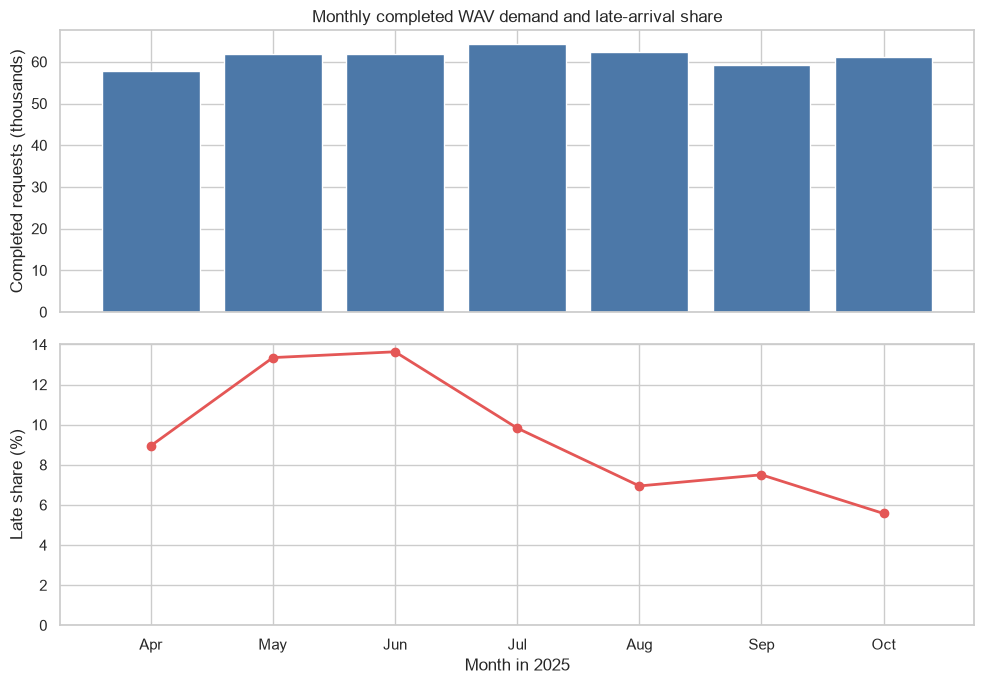

In [505]:
figure, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(10, 7),
    sharex=True,
)
axes[0].bar(
    monthly_service_risk_df["month_label"],
    monthly_service_risk_df["wav_request_count"] / 1_000,
    color="#4C78A8",
)
axes[0].set_ylabel("Completed requests (thousands)")
axes[0].set_title("Monthly completed WAV demand and late-arrival share")

axes[1].plot(
    monthly_service_risk_df["month_label"],
    100 * monthly_service_risk_df["late_share"],
    color="#E45756",
    marker="o",
    linewidth=2,
)
axes[1].set_xlabel("Month in 2025")
axes[1].set_ylabel("Late share (%)")
axes[1].set_ylim(bottom=0)
figure.tight_layout()
save_report_figure(figure, "wav_monthly_service_risk")
plt.show()

### Borough and time-block patterns

Compare count-weighted late shares across pickup boroughs and four-hour target periods.

In [506]:
borough_time_risk_df = (
    development_panel_df
    .groupby(
        ["borough", "time_block"],
        as_index=False,
        observed=True,
    )[["wav_request_count", "late_trip_count"]]
    .sum()
)
borough_time_risk_df["late_share"] = (
    borough_time_risk_df["late_trip_count"]
    / borough_time_risk_df["wav_request_count"]
)

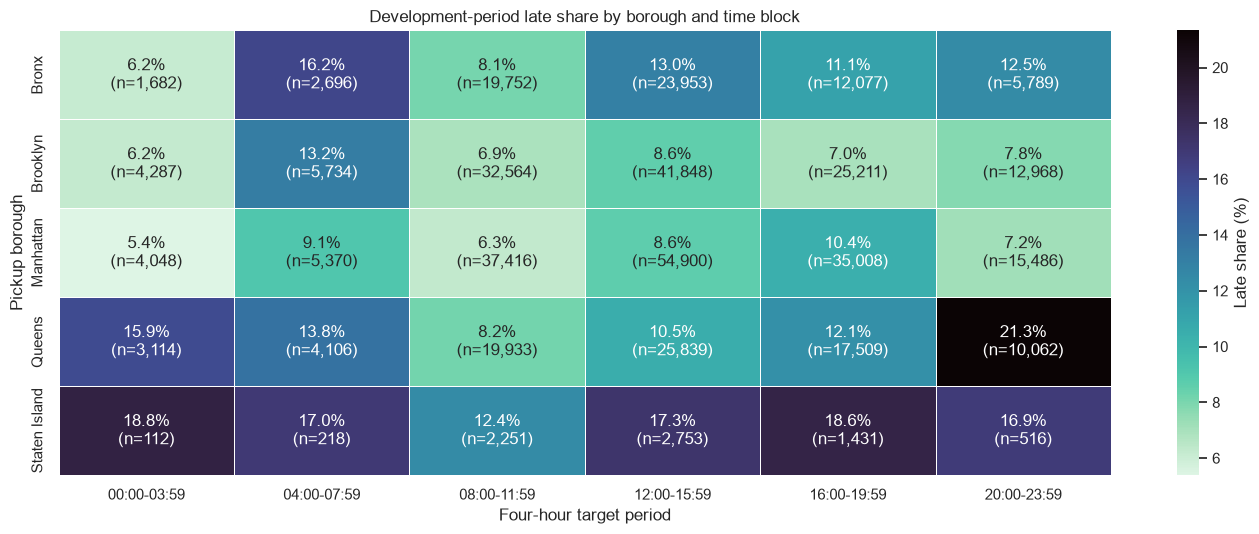

In [507]:
borough_time_rate_matrix = (
    borough_time_risk_df
    .pivot(index="borough", columns="time_block", values="late_share")
    .reindex(index=NYC_BOROUGHS, columns=TIME_BLOCK_ORDER)
)
borough_time_count_matrix = (
    borough_time_risk_df
    .pivot(
        index="borough",
        columns="time_block",
        values="wav_request_count",
    )
    .reindex(index=NYC_BOROUGHS, columns=TIME_BLOCK_ORDER)
)
borough_time_annotations = np.empty(
    borough_time_rate_matrix.shape,
    dtype=object,
)
for row_index, borough in enumerate(NYC_BOROUGHS):
    for column_index, time_block in enumerate(TIME_BLOCK_ORDER):
        late_share = borough_time_rate_matrix.loc[
            borough,
            time_block,
        ]
        request_count = int(
            borough_time_count_matrix.loc[borough, time_block]
        )
        borough_time_annotations[row_index, column_index] = (
            f"{late_share:.1%}\n(n={request_count:,})"
        )

figure, axis = plt.subplots(figsize=(14, 5.5))
sns.heatmap(
    100 * borough_time_rate_matrix,
    annot=borough_time_annotations,
    fmt="",
    cmap="mako_r",
    linewidths=0.5,
    cbar_kws={"label": "Late share (%)"},
    ax=axis,
)
axis.set_xlabel("Four-hour target period")
axis.set_ylabel("Pickup borough")
axis.set_title("Development-period late share by borough and time block")
figure.tight_layout()
save_report_figure(figure, "wav_borough_time_risk")
plt.show()

### Weather context

Compare late shares under normal and adverse weather for periods with complete hourly coverage.

In [508]:
weather_risk_input_df = development_panel_df.loc[
    development_panel_df["target_observed"]
    & development_panel_df["weather_coverage_share"].eq(1)
].copy()
weather_risk_input_df["adverse_weather"] = (
    weather_risk_input_df["observed_any_rain"].eq(True)
    | weather_risk_input_df["observed_any_snow"].eq(True)
    | weather_risk_input_df["observed_min_visibility_km"].lt(
        ADVERSE_VISIBILITY_THRESHOLD_KM
    )
    | weather_risk_input_df["observed_max_wind_speed_ms"].ge(
        ADVERSE_WIND_THRESHOLD_MS
    )
)
weather_risk_input_df["weather_category"] = np.where(
    weather_risk_input_df["adverse_weather"],
    "Adverse",
    "Normal",
)
weather_risk_summary_df = (
    weather_risk_input_df
    .groupby("weather_category", as_index=False)[
        ["wav_request_count", "late_trip_count"]
    ]
    .sum()
)
weather_risk_summary_df["late_share"] = (
    weather_risk_summary_df["late_trip_count"]
    / weather_risk_summary_df["wav_request_count"]
)
weather_risk_summary_df

,weather_category,wav_request_count,late_trip_count,late_share
0,Adverse,80424,9360,0.1164
1,Normal,336225,30137,0.0896


## 6.2 Taxi Zone geospatial evidence

Map development-period Taxi Zone support and late shares, displaying sub-threshold zones in neutral grey while retaining borough × four-hour periods as the forecasting unit.

In [509]:
zone_risk_summary_df = (
    development_wav_requests_df
    .groupBy("pickup_location_id")
    .agg(
        F.count("*").alias("wav_request_count"),
        F.sum("late_10").alias("late_trip_count"),
    )
    .orderBy("pickup_location_id")
    .toPandas()
)
zone_risk_summary_df["late_share"] = (
    zone_risk_summary_df["late_trip_count"]
    / zone_risk_summary_df["wav_request_count"]
)
zone_risk_summary_df["meets_support_threshold"] = (
    zone_risk_summary_df["wav_request_count"]
    >= MIN_ZONE_REQUEST_COUNT
)

if zone_risk_summary_df["wav_request_count"].sum() != (
    development_trip_count
):
    raise RuntimeError("Taxi Zone counts do not reconcile to EDA trips.")

In [510]:
zone_risk_map_gdf = taxi_zones_gdf.merge(
    zone_risk_summary_df[
        [
            "pickup_location_id",
            "wav_request_count",
            "late_trip_count",
            "late_share",
            "meets_support_threshold",
        ]
    ],
    on="pickup_location_id",
    how="left",
    validate="one_to_one",
)
zone_risk_map_gdf[["wav_request_count", "late_trip_count"]] = (
    zone_risk_map_gdf[
        ["wav_request_count", "late_trip_count"]
    ]
    .fillna(0)
    .astype("int64")
)
zone_risk_map_gdf["meets_support_threshold"] = (
    zone_risk_map_gdf["wav_request_count"]
    >= MIN_ZONE_REQUEST_COUNT
)
zone_risk_map_gdf["late_share_display_pct"] = np.where(
    zone_risk_map_gdf["meets_support_threshold"],
    100 * zone_risk_map_gdf["late_share"],
    np.nan,
)

supported_zone_count = int(
    zone_risk_map_gdf["meets_support_threshold"].sum()
)
supported_request_share = (
    zone_risk_map_gdf.loc[
        zone_risk_map_gdf["meets_support_threshold"],
        "wav_request_count",
    ].sum()
    / development_trip_count
)
print(
    f"Zones meeting the {MIN_ZONE_REQUEST_COUNT}-request rule: "
    f"{supported_zone_count:,} of {len(zone_risk_map_gdf):,}"
)
print(
    "Requests represented in the displayed risk map: "
    f"{supported_request_share:.2%}"
)

Zones meeting the 100-request rule: 241 of 263
Requests represented in the displayed risk map: 99.85%


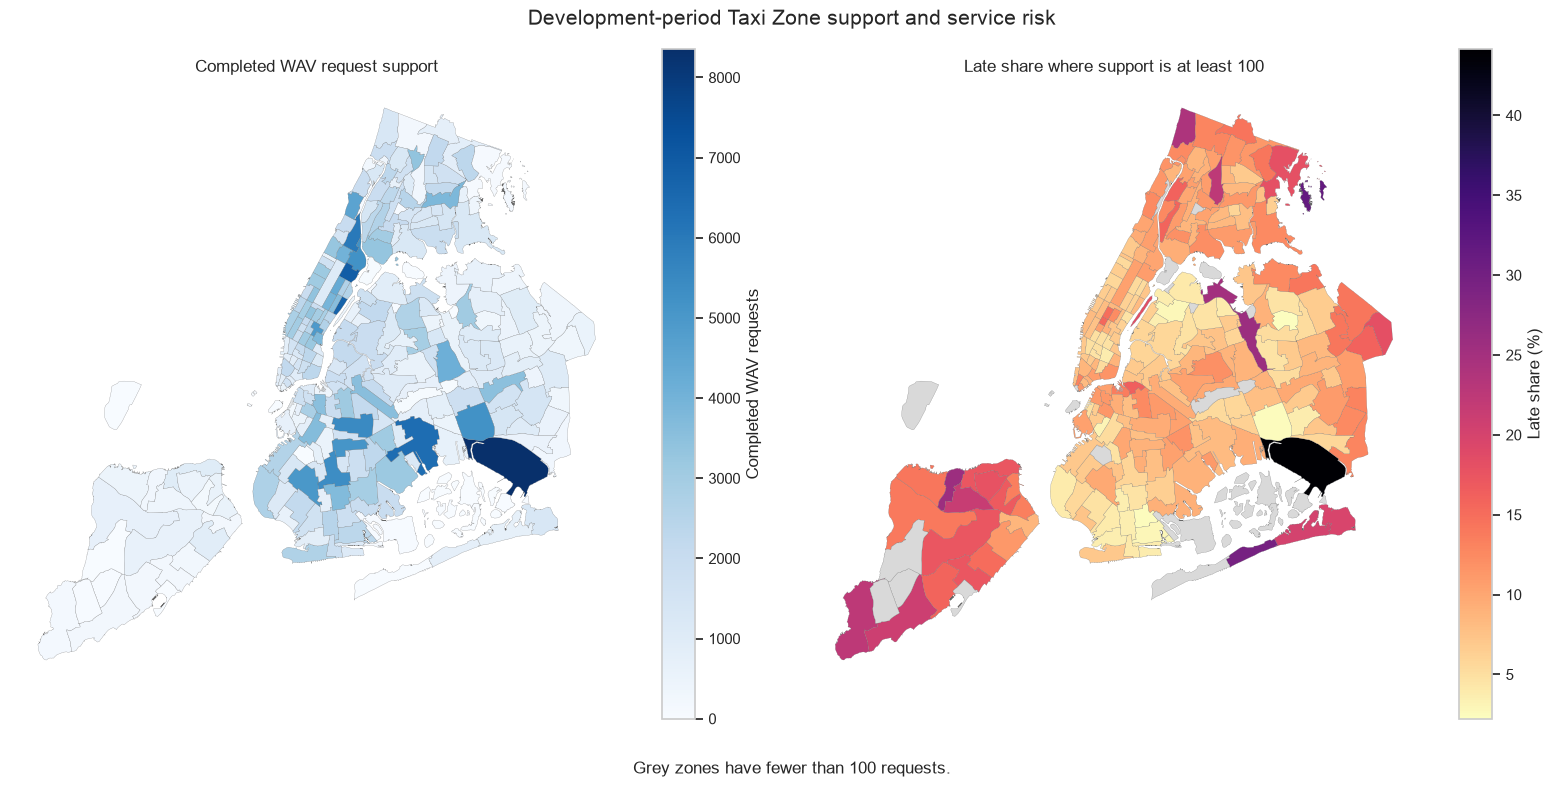

DataFrame[requested_pickup_datetime: timestamp_ntz, on_scene_datetime: timestamp_ntz, pickup_datetime: timestamp_ntz, pickup_location_id: int, pickup_zone: string, pickup_borough: string, arrival_offset_minutes: double, late_10: int, period_start: timestamp_ntz, month: int]

In [511]:
figure, axes = plt.subplots(1, 2, figsize=(16, 8))
zone_risk_map_gdf.plot(
    column="wav_request_count",
    cmap="Blues",
    linewidth=0.15,
    edgecolor="#666666",
    legend=True,
    legend_kwds={"label": "Completed WAV requests"},
    ax=axes[0],
)
axes[0].set_title("Completed WAV request support")
axes[0].set_axis_off()

zone_risk_map_gdf.plot(
    column="late_share_display_pct",
    cmap="magma_r",
    linewidth=0.15,
    edgecolor="#666666",
    legend=True,
    legend_kwds={"label": "Late share (%)"},
    missing_kwds={
        "color": "#D9D9D9",
        "label": f"Fewer than {MIN_ZONE_REQUEST_COUNT} requests",
    },
    ax=axes[1],
)
axes[1].set_title(
    f"Late share where support is at least {MIN_ZONE_REQUEST_COUNT}"
)
axes[1].set_axis_off()

figure.suptitle(
    "Development-period Taxi Zone support and service risk",
    fontsize=15,
)
figure.text(
    0.5,
    0.025,
    f"Grey zones have fewer than {MIN_ZONE_REQUEST_COUNT} requests.",
    ha="center",
)
figure.tight_layout(rect=(0, 0.06, 1, 1))
save_report_figure(figure, "wav_taxi_zone_support_and_risk")
plt.show()

development_wav_requests_df.unpersist()

# 7. Forecast design and persistence benchmark

Define the chronological split, forecast-time feature contract, evaluation metrics, and persistence benchmark before fitting the models.

## 7.1 Chronological split and forecast-time availability

Create April-August training data, September-October validation data, and a target-free November-December feature frame.

### Frozen candidate feature sets

Freeze the core and lagged-weather feature sets available to both model families before validation.

In [512]:
MODEL_KEY_COLUMNS = (
    "period_start",
    "borough",
    "split_label",
)
MODEL_TARGET_COLUMNS = (
    "wav_request_count",
    "late_trip_count",
    "late_share",
)

GLM_CATEGORICAL_FEATURES = (
    "borough_time_block",
    "day_of_week",
    "is_holiday",
)
XGB_CATEGORICAL_FEATURES = (
    "borough",
    "time_block",
    "day_of_week",
    "is_holiday",
)

CORE_CALENDAR_FEATURES = (
    "day_of_year_sin",
    "day_of_year_cos",
    "days_since_analysis_start",
)
CORE_HISTORY_FEATURES = (
    "log1p_lag_1_wav_request_count",
    "log1p_rolling_24h_wav_request_count",
    "log1p_lag_1_citywide_wav_request_count",
    "lag_1_late_share",
    "rolling_24h_late_share",
    "rolling_7d_late_share",
    "historical_same_slot_late_share",
    "lag_1_late_share_available",
    "rolling_24h_late_share_available",
    "rolling_7d_late_share_available",
    "same_slot_late_share_available",
)
WEATHER_CONTEXT_FEATURES = (
    "previous_period_mean_temperature_c",
    "previous_period_total_precipitation_mm",
    "previous_period_max_wind_speed_ms",
    "previous_period_min_visibility_km",
    "previous_period_any_rain",
    "previous_period_weather_coverage_share",
    "rolling_24h_precipitation_mm",
)

CORE_NUMERIC_MODEL_FEATURES = (
    *CORE_CALENDAR_FEATURES,
    *CORE_HISTORY_FEATURES,
)
WEATHER_NUMERIC_MODEL_FEATURES = (
    *CORE_NUMERIC_MODEL_FEATURES,
    *WEATHER_CONTEXT_FEATURES,
)
ALL_MODEL_PREDICTOR_COLUMNS = tuple(
    dict.fromkeys(
        GLM_CATEGORICAL_FEATURES
        + XGB_CATEGORICAL_FEATURES
        + WEATHER_NUMERIC_MODEL_FEATURES
    )
)
PANEL_MODEL_PREDICTOR_COLUMNS = tuple(
    feature_name
    for feature_name in ALL_MODEL_PREDICTOR_COLUMNS
    if feature_name != "borough_time_block"
)

In [513]:
FORBIDDEN_PREDICTOR_COLUMNS = {
    "wav_request_count",
    "late_trip_count",
    "late_share",
    "target_observed",
    "citywide_wav_request_count",
    "observed_mean_temperature_c",
    "observed_total_precipitation_mm",
    "observed_max_wind_speed_ms",
    "observed_min_visibility_km",
    "observed_any_rain",
    "observed_any_snow",
}
leaking_predictors = FORBIDDEN_PREDICTOR_COLUMNS.intersection(
    ALL_MODEL_PREDICTOR_COLUMNS
)

if leaking_predictors:
    raise RuntimeError(
        f"Target-period predictors entered the model: {leaking_predictors}"
    )
if not set(PANEL_MODEL_PREDICTOR_COLUMNS).issubset(
    saved_curated_wav_panel_df.columns
):
    raise KeyError("The curated panel is missing frozen predictors.")

In [514]:
def add_borough_time_block(data: pd.DataFrame) -> pd.DataFrame:
    """
    Add the pre-specified borough and four-hour interaction category.
    """
    enriched_data = data.copy()
    enriched_data["borough_time_block"] = (
        enriched_data["borough"].astype("string")
        + " | "
        + enriched_data["time_block"].astype("string")
    )
    return enriched_data


development_model_columns = tuple(
    dict.fromkeys(
        MODEL_KEY_COLUMNS
        + MODEL_TARGET_COLUMNS
        + PANEL_MODEL_PREDICTOR_COLUMNS
    )
)
future_feature_columns = tuple(
    dict.fromkeys(
        MODEL_KEY_COLUMNS + PANEL_MODEL_PREDICTOR_COLUMNS
    )
)

training_model_mask = (
    saved_curated_wav_panel_df["split_label"].eq("training")
    & saved_curated_wav_panel_df["target_observed"]
)
validation_model_mask = (
    saved_curated_wav_panel_df["split_label"].eq("validation")
    & saved_curated_wav_panel_df["target_observed"]
)
future_test_mask = saved_curated_wav_panel_df["split_label"].eq(
    "test"
)

model_training_df = add_borough_time_block(
    saved_curated_wav_panel_df.loc[
        training_model_mask,
        development_model_columns,
    ]
)
model_validation_df = add_borough_time_block(
    saved_curated_wav_panel_df.loc[
        validation_model_mask,
        development_model_columns,
    ]
)
future_test_features_df = add_borough_time_block(
    saved_curated_wav_panel_df.loc[
        future_test_mask,
        future_feature_columns,
    ]
)
model_development_df = pd.concat(
    [model_training_df, model_validation_df],
    ignore_index=True,
)

future_target_columns = set(MODEL_TARGET_COLUMNS).intersection(
    future_test_features_df.columns
)
if future_target_columns:
    raise RuntimeError(
        f"Future feature frame contains targets: {future_target_columns}"
    )

In [515]:
period_start = saved_curated_wav_panel_df["period_start"]
expected_split_labels = np.select(
    [
        period_start < pd.Timestamp(TRAIN_END_EXCLUSIVE),
        period_start < pd.Timestamp(VALIDATION_END_EXCLUSIVE),
    ],
    ["training", "validation"],
    default="test",
)
if not np.array_equal(
    saved_curated_wav_panel_df["split_label"].to_numpy(),
    expected_split_labels,
):
    raise RuntimeError("Saved split labels do not match the fixed dates.")

split_summary_df = pd.DataFrame(
    [
        {
            "split": "Training",
            "period": "April-August 2025",
            "panel_rows": int(
                saved_curated_wav_panel_df["split_label"]
                .eq("training")
                .sum()
            ),
            "scoreable_rows": len(model_training_df),
        },
        {
            "split": "Validation",
            "period": "September-October 2025",
            "panel_rows": int(
                saved_curated_wav_panel_df["split_label"]
                .eq("validation")
                .sum()
            ),
            "scoreable_rows": len(model_validation_df),
        },
        {
            "split": "Test",
            "period": "November-December 2025",
            "panel_rows": len(future_test_features_df),
            "scoreable_rows": pd.NA,
        },
    ]
)
split_summary_df

,split,period,panel_rows,scoreable_rows
0,Training,April-August 2025,4590,4438
1,Validation,September-October 2025,1830,1734
2,Test,November-December 2025,1830,<NA>


## 7.2 Persistence benchmark

Create a previous-24-hour count-weighted persistence forecast with training-period borough and citywide fallbacks.

In [516]:
training_borough_fallback_df = (
    model_training_df
    .groupby("borough", as_index=False)
    .agg(
        late_trip_count=("late_trip_count", "sum"),
        wav_request_count=("wav_request_count", "sum"),
    )
)
training_borough_fallback_df["borough_training_late_share"] = (
    training_borough_fallback_df["late_trip_count"]
    / training_borough_fallback_df["wav_request_count"]
)
training_global_late_share = (
    model_training_df["late_trip_count"].sum()
    / model_training_df["wav_request_count"].sum()
)

if not 0 <= training_global_late_share <= 1:
    raise ValueError("Training fallback is outside the probability range.")

In [517]:
BENCHMARK_PREDICTION_COLUMNS = {
    "24-hour persistence": "persistence_24h_prediction",
}
benchmark_source_columns = (
    *MODEL_KEY_COLUMNS,
    "rolling_24h_late_share",
)
benchmark_forecast_source_df = pd.concat(
    [
        model_validation_df.loc[:, benchmark_source_columns],
        future_test_features_df.loc[:, benchmark_source_columns],
    ],
    ignore_index=True,
)
benchmark_forecast_source_df = benchmark_forecast_source_df.merge(
    training_borough_fallback_df[
        ["borough", "borough_training_late_share"]
    ],
    on="borough",
    how="left",
    validate="many_to_one",
)

borough_fallback_values = benchmark_forecast_source_df[
    "borough_training_late_share"
].fillna(training_global_late_share)
benchmark_forecast_source_df["persistence_24h_prediction"] = (
    benchmark_forecast_source_df["rolling_24h_late_share"]
    .fillna(borough_fallback_values)
)
benchmark_forecast_source_df["persistence_fallback_used"] = (
    benchmark_forecast_source_df["rolling_24h_late_share"].isna()
)

benchmark_output_columns = (
    *MODEL_KEY_COLUMNS,
    *BENCHMARK_PREDICTION_COLUMNS.values(),
    "persistence_fallback_used",
)
benchmark_forecasts_df = (
    benchmark_forecast_source_df.loc[:, benchmark_output_columns]
    .sort_values(["period_start", "borough"])
    .reset_index(drop=True)
)

benchmark_prediction_values = benchmark_forecasts_df[
    list(BENCHMARK_PREDICTION_COLUMNS.values())
]
if benchmark_prediction_values.isna().any().any():
    raise RuntimeError("Benchmark forecasts contain missing predictions.")
if not (
    benchmark_prediction_values.ge(0).all().all()
    and benchmark_prediction_values.le(1).all().all()
):
    raise ValueError("Benchmark forecasts are outside [0, 1].")
if set(MODEL_TARGET_COLUMNS).intersection(
    benchmark_forecasts_df.columns
):
    raise RuntimeError("Benchmark forecasts contain protected targets.")

## 7.3 Evaluation criteria

Use request-weighted MAE for model selection and retain weighted RMSE, unweighted MAE, calibration, and subgroup diagnostics for evaluation.

In [518]:
PRIMARY_SELECTION_METRIC = "weighted_mae"
MODEL_SELECTION_MAE_TOLERANCE = 0.001
HIGH_RISK_THRESHOLD = 0.10
CALIBRATION_BIN_COUNT = 10
TOP_RISK_CAPTURE_SHARE = 0.10
REQUEST_VOLUME_BIN_EDGES = (0, 10, 50, 100, np.inf)
REQUEST_VOLUME_BIN_LABELS = (
    "1-10 requests",
    "11-50 requests",
    "51-100 requests",
    "More than 100 requests",
)

In [519]:
def calculate_forecast_metrics(
    evaluation_data: pd.DataFrame,
    prediction_column: str,
    model_name: str,
    evaluation_group: str = "Overall",
) -> dict[str, float | int | str]:
    """
    Calculate count-weighted and unweighted forecast-error metrics.

    Args:
        evaluation_data: Scoreable rows with targets, weights, and forecasts.
        prediction_column: Column containing predicted late shares.
        model_name: Human-readable model or benchmark name.
        evaluation_group: Population label for the returned record.

    Returns:
        One metric record containing errors, calibration, and support.

    Raises:
        ValueError: If rows, weights, targets, or predictions are invalid.
        KeyError: If a required scoring column is missing.
    """
    required_columns = {
        "split_label",
        "wav_request_count",
        "late_share",
        prediction_column,
    }
    missing_columns = required_columns.difference(
        evaluation_data.columns
    )
    if missing_columns:
        raise KeyError(f"Missing scoring columns: {missing_columns}")
    if evaluation_data.empty:
        raise ValueError("Forecast metrics require at least one row.")
    if evaluation_data[list(required_columns)].isna().any().any():
        raise ValueError("Forecast metrics cannot score missing values.")

    observed_values = evaluation_data["late_share"].to_numpy(
        dtype=float
    )
    predicted_values = evaluation_data[prediction_column].to_numpy(
        dtype=float
    )
    request_weights = evaluation_data["wav_request_count"].to_numpy(
        dtype=float
    )
    if (request_weights <= 0).any():
        raise ValueError("Scoring weights must be strictly positive.")
    if not np.isfinite(observed_values).all():
        raise ValueError("Observed late shares must be finite.")
    if not np.isfinite(predicted_values).all():
        raise ValueError("Predicted late shares must be finite.")
    if ((predicted_values < 0) | (predicted_values > 1)).any():
        raise ValueError("Predicted late shares must lie in [0, 1].")

    split_labels = evaluation_data["split_label"].unique()
    if len(split_labels) != 1:
        raise ValueError("One metric record must represent one split.")

    weighted_mae = mean_absolute_error(
        observed_values,
        predicted_values,
        sample_weight=request_weights,
    )
    weighted_rmse = root_mean_squared_error(
        observed_values,
        predicted_values,
        sample_weight=request_weights,
    )
    unweighted_mae = mean_absolute_error(
        observed_values,
        predicted_values,
    )
    observed_weighted_share = np.average(
        observed_values,
        weights=request_weights,
    )
    predicted_weighted_share = np.average(
        predicted_values,
        weights=request_weights,
    )

    return {
        "model_name": model_name,
        "split_label": str(split_labels[0]),
        "evaluation_group": evaluation_group,
        "row_count": len(evaluation_data),
        "wav_request_count": int(request_weights.sum()),
        "weighted_mae": weighted_mae,
        "weighted_mae_percentage_points": 100 * weighted_mae,
        "weighted_rmse": weighted_rmse,
        "weighted_rmse_percentage_points": 100 * weighted_rmse,
        "unweighted_mae": unweighted_mae,
        "unweighted_mae_percentage_points": 100 * unweighted_mae,
        "observed_weighted_late_share": observed_weighted_share,
        "predicted_weighted_late_share": predicted_weighted_share,
        "calibration_gap_percentage_points": (
            100
            * (predicted_weighted_share - observed_weighted_share)
        ),
    }

In [520]:
validation_benchmark_scoring_df = (
    model_validation_df[
        [*MODEL_KEY_COLUMNS, *MODEL_TARGET_COLUMNS]
    ]
    .merge(
        benchmark_forecasts_df.loc[
            benchmark_forecasts_df["split_label"].eq("validation")
        ],
        on=list(MODEL_KEY_COLUMNS),
        how="left",
        validate="one_to_one",
    )
)
if len(validation_benchmark_scoring_df) != len(model_validation_df):
    raise RuntimeError("Validation benchmark merge changed row count.")

validation_benchmark_metrics_df = pd.DataFrame(
    [
        calculate_forecast_metrics(
            validation_benchmark_scoring_df,
            prediction_column,
            benchmark_name,
        )
        for benchmark_name, prediction_column in (
            BENCHMARK_PREDICTION_COLUMNS.items()
        )
    ]
)
validation_benchmark_metrics_df[
    [
        "model_name",
        "weighted_mae_percentage_points",
        "weighted_rmse_percentage_points",
        "unweighted_mae_percentage_points",
    ]
]

,model_name,weighted_mae_percentage_points,weighted_rmse_percentage_points,unweighted_mae_percentage_points
0,24-hour persistence,2.8963,4.2343,5.3726


# 8. Forecasting models

Fit and validate a grouped-binomial GLM and weighted XGBoost, then refit the selected specifications on April-October to forecast November-December.

## 8.1 Model 1: Grouped Binomial Logistic Regression

Model each borough-period through its grouped late and on-time completed-trip counts using a binomial likelihood.

### 8.1.1 Model matrix and grouped-binomial formulation

Fit training-only imputation, scaling, and reference-level encoding before constructing a full-rank grouped-binomial design matrix.

In [521]:
GLM_FEATURE_SPECIFICATIONS = {
    "core": {
        "categorical_features": GLM_CATEGORICAL_FEATURES,
        "numeric_features": CORE_NUMERIC_MODEL_FEATURES,
    },
    "weather": {
        "categorical_features": GLM_CATEGORICAL_FEATURES,
        "numeric_features": WEATHER_NUMERIC_MODEL_FEATURES,
    },
}
GLM_CLUSTER_FREQUENCY = "W-SUN"

pd.DataFrame(
    [
        {
            "specification": specification_name,
            "categorical_feature_count": len(
                specification["categorical_features"]
            ),
            "numeric_feature_count": len(
                specification["numeric_features"]
            ),
        }
        for specification_name, specification in (
            GLM_FEATURE_SPECIFICATIONS.items()
        )
    ]
)

,specification,categorical_feature_count,numeric_feature_count
0,core,3,14
1,weather,3,21


In [522]:
def build_model_preprocessor(
    categorical_features: tuple[str, ...],
    numeric_features: tuple[str, ...],
    *,
    standardise_numeric: bool,
    drop_first_category: bool,
) -> ColumnTransformer:
    """
    Build a training-fitted preprocessing pipeline for model predictors.

    Args:
        categorical_features: Categorical columns to impute and encode.
        numeric_features: Numerical columns to impute and optionally scale.
        standardise_numeric: Whether to centre and scale numerical columns.
        drop_first_category: Whether to omit one reference category per factor.

    Returns:
        An unfitted column transformer with deterministic feature names.
    """
    categorical_pipeline = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent",
                    keep_empty_features=True,
                ),
            ),
            (
                "encoder",
                OneHotEncoder(
                    drop="first" if drop_first_category else None,
                    handle_unknown="ignore",
                    sparse_output=False,
                ),
            ),
        ]
    )

    numeric_steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                keep_empty_features=True,
            ),
        )
    ]
    if standardise_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    return ColumnTransformer(
        transformers=[
            (
                "categorical",
                categorical_pipeline,
                list(categorical_features),
            ),
            ("numeric", Pipeline(numeric_steps), list(numeric_features)),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

In [523]:
def build_grouped_binomial_outcome(
    modelling_data: pd.DataFrame,
) -> np.ndarray:
    """
    Construct explicit grouped late and on-time counts for a binomial GLM.

    Args:
        modelling_data: Scoreable borough-period rows with grouped counts.

    Returns:
        A two-column array containing late and on-time completed trips.

    Raises:
        ValueError: If counts are missing, negative, or internally inconsistent.
    """
    required_columns = {"late_trip_count", "wav_request_count"}
    if not required_columns.issubset(modelling_data.columns):
        raise KeyError("Grouped outcome columns are missing.")

    late_counts = modelling_data["late_trip_count"].to_numpy(dtype=float)
    request_counts = modelling_data["wav_request_count"].to_numpy(
        dtype=float
    )
    on_time_counts = request_counts - late_counts

    grouped_counts = np.column_stack([late_counts, on_time_counts])
    if not np.isfinite(grouped_counts).all():
        raise ValueError("Grouped outcome contains non-finite counts.")
    if (grouped_counts < 0).any() or (request_counts <= 0).any():
        raise ValueError("Grouped outcome counts must be valid and positive.")

    return grouped_counts

In [524]:
def fit_grouped_binomial_model(
    fitting_data: pd.DataFrame,
    prediction_data: pd.DataFrame,
    categorical_features: tuple[str, ...],
    numeric_features: tuple[str, ...],
) -> dict[str, object]:
    """
    Fit a grouped-binomial GLM and predict a later chronological period.

    The encoder, imputer, and scaler are fitted only on fitting_data. Weekly
    cluster-robust covariance is used for coefficient uncertainty, while
    predictions follow the grouped-binomial mean model.

    Args:
        fitting_data: Rows containing predictors and grouped outcomes.
        prediction_data: Later rows requiring probability forecasts.
        categorical_features: Frozen categorical predictors.
        numeric_features: Frozen numerical predictors.

    Returns:
        Fitted preprocessing and GLM objects, forecasts, and diagnostics.

    Raises:
        RuntimeError: If the design is rank deficient or fitting fails.
        ValueError: If predictions fall outside the probability range.
    """
    predictor_columns = (*categorical_features, *numeric_features)
    preprocessor = build_model_preprocessor(
        categorical_features,
        numeric_features,
        standardise_numeric=True,
        drop_first_category=True,
    )
    fitting_matrix = preprocessor.fit_transform(
        fitting_data.loc[:, predictor_columns]
    )
    prediction_matrix = preprocessor.transform(
        prediction_data.loc[:, predictor_columns]
    )
    feature_names = tuple(preprocessor.get_feature_names_out())

    fitting_design = pd.DataFrame(
        fitting_matrix,
        columns=feature_names,
        index=fitting_data.index,
    )
    prediction_design = pd.DataFrame(
        prediction_matrix,
        columns=feature_names,
        index=prediction_data.index,
    )
    fitting_design = sm.add_constant(
        fitting_design,
        has_constant="add",
    )
    prediction_design = sm.add_constant(
        prediction_design,
        has_constant="add",
    )

    duplicate_column_mask = fitting_design.T.duplicated(
        keep="first"
    )
    dropped_duplicate_columns = tuple(
        fitting_design.columns[duplicate_column_mask]
    )
    if dropped_duplicate_columns:
        fitting_design = fitting_design.loc[
            :, ~duplicate_column_mask
        ]
        prediction_design = prediction_design.loc[
            :, ~duplicate_column_mask
        ]

    design_rank = int(
        np.linalg.matrix_rank(fitting_design.to_numpy(dtype=float))
    )
    if design_rank != fitting_design.shape[1]:
        raise RuntimeError(
            "Grouped-binomial design matrix is not full rank: "
            f"{design_rank} of {fitting_design.shape[1]} columns."
        )

    grouped_outcome = build_grouped_binomial_outcome(fitting_data)
    cluster_groups = (
        fitting_data["period_start"]
        .dt.to_period(GLM_CLUSTER_FREQUENCY)
        .astype(str)
    )
    glm_model = sm.GLM(
        endog=grouped_outcome,
        exog=fitting_design,
        family=sm.families.Binomial(),
    )
    glm_result = glm_model.fit(
        cov_type="cluster",
        cov_kwds={"groups": cluster_groups},
    )
    if not glm_result.converged:
        raise RuntimeError("Grouped-binomial GLM did not converge.")

    predicted_probabilities = np.asarray(
        glm_result.predict(prediction_design),
        dtype=float,
    )
    if not np.isfinite(predicted_probabilities).all():
        raise ValueError("Grouped-binomial predictions are not finite.")
    if (
        (predicted_probabilities < 0)
        | (predicted_probabilities > 1)
    ).any():
        raise ValueError("Grouped-binomial predictions are outside [0, 1].")

    pearson_dispersion = float(
        np.square(glm_result.resid_pearson).sum()
        / glm_result.df_resid
    )
    return {
        "preprocessor": preprocessor,
        "result": glm_result,
        "fitting_design": fitting_design,
        "prediction_design": prediction_design,
        "predictions": predicted_probabilities,
        "design_rank": design_rank,
        "parameter_count": fitting_design.shape[1],
        "cluster_count": int(cluster_groups.nunique()),
        "dropped_duplicate_columns": (
            dropped_duplicate_columns
        ),
        "pearson_dispersion": pearson_dispersion,
    }

In [525]:
glm_candidate_fits = {}
glm_validation_metric_records = []

for specification_name, specification in (
    GLM_FEATURE_SPECIFICATIONS.items()
):
    glm_candidate_fit = fit_grouped_binomial_model(
        fitting_data=model_training_df,
        prediction_data=model_validation_df,
        categorical_features=specification["categorical_features"],
        numeric_features=specification["numeric_features"],
    )
    prediction_column = (
        f"glm_{specification_name}_validation_prediction"
    )
    candidate_scoring_df = model_validation_df[
        [*MODEL_KEY_COLUMNS, *MODEL_TARGET_COLUMNS]
    ].copy()
    candidate_scoring_df[prediction_column] = glm_candidate_fit[
        "predictions"
    ]

    candidate_metrics = calculate_forecast_metrics(
        candidate_scoring_df,
        prediction_column,
        f"Grouped Binomial GLM ({specification_name})",
    )
    candidate_metrics["specification"] = specification_name
    glm_validation_metric_records.append(candidate_metrics)

    glm_candidate_fit["validation_scoring_df"] = candidate_scoring_df
    glm_candidate_fit["prediction_column"] = prediction_column
    glm_candidate_fits[specification_name] = glm_candidate_fit

In [526]:
glm_validation_candidate_metrics_df = (
    pd.DataFrame(glm_validation_metric_records)
    .sort_values(PRIMARY_SELECTION_METRIC)
    .reset_index(drop=True)
)
glm_validation_candidate_metrics_df[
    [
        "specification",
        "weighted_mae_percentage_points",
        "weighted_rmse_percentage_points",
        "unweighted_mae_percentage_points",
    ]
]

,specification,weighted_mae_percentage_points,weighted_rmse_percentage_points,unweighted_mae_percentage_points
0,weather,2.5812,3.7052,4.8721
1,core,2.5917,3.7854,4.7880


### Frozen GLM selection rule

Select by validation weighted MAE, retaining the core specification when it is within the pre-declared 0.1 percentage-point simplicity tolerance.

In [527]:
best_glm_weighted_mae = float(
    glm_validation_candidate_metrics_df[
        PRIMARY_SELECTION_METRIC
    ].min()
)
core_glm_weighted_mae = float(
    glm_validation_candidate_metrics_df.loc[
        glm_validation_candidate_metrics_df[
            "specification"
        ].eq("core"),
        PRIMARY_SELECTION_METRIC,
    ].iloc[0]
)

if (
    core_glm_weighted_mae
    <= best_glm_weighted_mae + MODEL_SELECTION_MAE_TOLERANCE
):
    selected_glm_specification = "core"
else:
    selected_glm_specification = str(
        glm_validation_candidate_metrics_df.iloc[0][
            "specification"
        ]
    )

selected_glm_candidate_fit = glm_candidate_fits[
    selected_glm_specification
]
selected_glm_prediction_column = (
    selected_glm_candidate_fit["prediction_column"]
)
selected_glm_validation_scoring_df = (
    selected_glm_candidate_fit["validation_scoring_df"].copy()
)

print(f"Selected GLM specification: {selected_glm_specification}")
glm_validation_candidate_metrics_df.loc[
    glm_validation_candidate_metrics_df["specification"].eq(
        selected_glm_specification
    )
]

Selected GLM specification: core


,model_name,split_label,evaluation_group,row_count,wav_request_count,weighted_mae,weighted_mae_percentage_points,weighted_rmse,weighted_rmse_percentage_points,unweighted_mae,unweighted_mae_percentage_points,observed_weighted_late_share,predicted_weighted_late_share,calibration_gap_percentage_points,specification
1,Grouped Binomial GLM (core),validation,Overall,1734,120416,0.0259,2.5917,0.0379,3.7854,0.0479,4.7880,0.0652,0.0550,-1.0181,core


### 8.1.2 Fitting, diagnostics, and interpretation

Fit the grouped-binomial model, record diagnostics, and refit the selected specification for future forecasting.

In [528]:
def build_weighted_calibration_table(
    evaluation_data: pd.DataFrame,
    prediction_column: str,
    model_name: str,
    bin_count: int = CALIBRATION_BIN_COUNT,
) -> pd.DataFrame:
    """
    Summarise observed and predicted risk in weighted forecast-risk bins.

    Args:
        evaluation_data: Scoreable rows with grouped outcomes and forecasts.
        prediction_column: Column containing predicted late shares.
        model_name: Label recorded in the returned table.
        bin_count: Number of equal-row forecast-risk groups.

    Returns:
        One row per calibration bin with request-weighted risk estimates.
    """
    calibration_data = evaluation_data.copy()
    forecast_ranks = calibration_data[prediction_column].rank(
        method="first"
    )
    calibration_data["calibration_bin"] = (
        pd.qcut(
            forecast_ranks,
            q=bin_count,
            labels=False,
            duplicates="drop",
        )
        + 1
    )
    calibration_data["weighted_prediction_total"] = (
        calibration_data[prediction_column]
        * calibration_data["wav_request_count"]
    )

    calibration_table = (
        calibration_data
        .groupby("calibration_bin", as_index=False, observed=True)
        .agg(
            row_count=("period_start", "size"),
            wav_request_count=("wav_request_count", "sum"),
            late_trip_count=("late_trip_count", "sum"),
            mean_predicted_risk=(
                "weighted_prediction_total",
                "sum",
            ),
            minimum_prediction=(prediction_column, "min"),
            maximum_prediction=(prediction_column, "max"),
        )
    )
    calibration_table["observed_late_share"] = (
        calibration_table["late_trip_count"]
        / calibration_table["wav_request_count"]
    )
    calibration_table["predicted_late_share"] = (
        calibration_table["mean_predicted_risk"]
        / calibration_table["wav_request_count"]
    )
    calibration_table.insert(0, "model_name", model_name)
    return calibration_table.drop(columns="mean_predicted_risk")

In [529]:
selected_glm_features = GLM_FEATURE_SPECIFICATIONS[
    selected_glm_specification
]
final_glm_fit = fit_grouped_binomial_model(
    fitting_data=model_development_df,
    prediction_data=future_test_features_df,
    categorical_features=selected_glm_features[
        "categorical_features"
    ],
    numeric_features=selected_glm_features["numeric_features"],
)
glm_future_forecasts_df = future_test_features_df[
    list(MODEL_KEY_COLUMNS)
].copy()
glm_future_forecasts_df["grouped_binomial_glm_prediction"] = (
    final_glm_fit["predictions"]
)

if set(MODEL_TARGET_COLUMNS).intersection(
    glm_future_forecasts_df.columns
):
    raise RuntimeError("GLM future forecasts contain protected targets.")

In [530]:
final_glm_result = final_glm_fit["result"]
coefficient_confidence_intervals = np.asarray(
    final_glm_result.conf_int()
)
glm_coefficient_terms = final_glm_fit[
    "fitting_design"
].columns.to_list()

glm_coefficients_df = pd.DataFrame(
    {
        "term": glm_coefficient_terms,
        "coefficient": np.asarray(final_glm_result.params),
        "cluster_robust_standard_error": np.asarray(
            final_glm_result.bse
        ),
        "p_value": np.asarray(final_glm_result.pvalues),
        "confidence_interval_lower": (
            coefficient_confidence_intervals[:, 0]
        ),
        "confidence_interval_upper": (
            coefficient_confidence_intervals[:, 1]
        ),
    }
)
glm_coefficients_df["odds_ratio"] = np.exp(
    glm_coefficients_df["coefficient"].clip(-50, 50)
)
glm_coefficients_df.to_csv(
    MODEL_OUTPUT_ROOT / "wav_glm_coefficients.csv",
    index=False,
)

# Numeric terms are standardised using training-set means and scales.
glm_numeric_coefficient_summary_df = (
    glm_coefficients_df.loc[
        glm_coefficients_df["term"].isin(
            selected_glm_features["numeric_features"]
        )
        & ~glm_coefficients_df["term"].str.endswith(
            "_available"
        )
    ]
    .assign(
        standardised_coefficient=lambda data: data[
            "coefficient"
        ],
        odds_ratio_per_training_standard_deviation=lambda data: (
            data["odds_ratio"]
        ),
        p_value_display=lambda data: data["p_value"].map(
            lambda p_value: (
                "<0.0001"
                if p_value < 0.0001
                else f"{p_value:.4f}"
            )
        ),
        absolute_coefficient=lambda data: (
            data["coefficient"].abs()
        ),
    )
    .nlargest(8, "absolute_coefficient")
    .loc[
        :,
        [
            "term",
            "standardised_coefficient",
            "odds_ratio_per_training_standard_deviation",
            "p_value_display",
        ],
    ]
)
glm_numeric_coefficient_summary_df

,term,standardised_coefficient,odds_ratio_per_training_standard_deviation,p_value_display
46,historical_same_slot_late_share,0.2601,1.2971,<0.0001
44,rolling_24h_late_share,0.2323,1.2615,<0.0001
37,day_of_year_sin,0.2153,1.2403,0.1250
41,log1p_rolling_24h_wav_request_count,0.1732,1.1891,0.0039
45,rolling_7d_late_share,0.1221,1.1299,0.0162
39,days_since_analysis_start,0.0946,1.0992,0.4933
40,log1p_lag_1_wav_request_count,0.0929,1.0973,0.1308
43,lag_1_late_share,0.0721,1.0747,<0.0001


## 8.2 Model 2: Weighted XGBoost

Fit a nonlinear logistic-objective XGBoost regressor using completed-request counts as observation weights.

### 8.2.1 Validation, early stopping, and final fitting

Validate six pre-declared regularised candidates with early stopping and the same simplicity tolerance used for the GLM.

In [531]:
XGB_FEATURE_SPECIFICATIONS = {
    "core": {
        "categorical_features": XGB_CATEGORICAL_FEATURES,
        "numeric_features": CORE_NUMERIC_MODEL_FEATURES,
    },
    "weather": {
        "categorical_features": XGB_CATEGORICAL_FEATURES,
        "numeric_features": WEATHER_NUMERIC_MODEL_FEATURES,
    },
}

XGB_N_JOBS = 4
XGB_MAX_ESTIMATORS = 3000
XGB_EARLY_STOPPING_ROUNDS = 100
XGB_VALIDATION_CANDIDATES = (
    {
        "candidate_name": "core_regularised",
        "feature_specification": "core",
        "complexity_rank": 1,
        "max_depth": 2,
        "learning_rate": 0.05,
        "min_child_weight": 20,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 5,
    },
    {
        "candidate_name": "core_balanced",
        "feature_specification": "core",
        "complexity_rank": 2,
        "max_depth": 3,
        "learning_rate": 0.05,
        "min_child_weight": 20,
        "subsample": 0.8,
        "colsample_bytree": 1.0,
        "reg_lambda": 5,
    },
    {
        "candidate_name": "core_flexible",
        "feature_specification": "core",
        "complexity_rank": 3,
        "max_depth": 4,
        "learning_rate": 0.03,
        "min_child_weight": 5,
        "subsample": 1.0,
        "colsample_bytree": 0.8,
        "reg_lambda": 5,
    },
    {
        "candidate_name": "weather_regularised",
        "feature_specification": "weather",
        "complexity_rank": 4,
        "max_depth": 2,
        "learning_rate": 0.05,
        "min_child_weight": 20,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 5,
    },
    {
        "candidate_name": "weather_balanced",
        "feature_specification": "weather",
        "complexity_rank": 5,
        "max_depth": 3,
        "learning_rate": 0.05,
        "min_child_weight": 20,
        "subsample": 0.8,
        "colsample_bytree": 1.0,
        "reg_lambda": 5,
    },
    {
        "candidate_name": "weather_responsive",
        "feature_specification": "weather",
        "complexity_rank": 6,
        "max_depth": 3,
        "learning_rate": 0.10,
        "min_child_weight": 5,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 1,
    },
)

In [532]:
xgb_preprocessed_data = {}

for specification_name, specification in (
    XGB_FEATURE_SPECIFICATIONS.items()
):
    predictor_columns = (
        *specification["categorical_features"],
        *specification["numeric_features"],
    )
    preprocessor = build_model_preprocessor(
        specification["categorical_features"],
        specification["numeric_features"],
        standardise_numeric=False,
        drop_first_category=False,
    )
    training_matrix = preprocessor.fit_transform(
        model_training_df.loc[:, predictor_columns]
    )
    validation_matrix = preprocessor.transform(
        model_validation_df.loc[:, predictor_columns]
    )

    xgb_preprocessed_data[specification_name] = {
        "preprocessor": preprocessor,
        "predictor_columns": predictor_columns,
        "training_matrix": training_matrix,
        "validation_matrix": validation_matrix,
    }

In [533]:
def build_xgboost_model(
    configuration: dict[str, float | int | str],
    n_estimators: int,
    early_stopping_rounds: int | None = None,
) -> XGBRegressor:
    """
    Build an XGBoost regressor from one frozen configuration.

    Args:
        configuration: Frozen feature and hyperparameter settings.
        n_estimators: Maximum or selected number of boosting trees.
        early_stopping_rounds: Optional validation stopping patience.

    Returns:
        An unfitted, reproducibly configured XGBoost estimator.
    """
    model_parameters = {
        "objective": "reg:logistic",
        "n_estimators": n_estimators,
        "eval_metric": "mae",
        "random_state": RANDOM_SEED,
        "n_jobs": XGB_N_JOBS,
        "tree_method": "hist",
        "max_depth": configuration["max_depth"],
        "learning_rate": configuration["learning_rate"],
        "min_child_weight": configuration["min_child_weight"],
        "subsample": configuration["subsample"],
        "colsample_bytree": configuration["colsample_bytree"],
        "reg_lambda": configuration["reg_lambda"],
    }
    if early_stopping_rounds is not None:
        model_parameters["early_stopping_rounds"] = (
            early_stopping_rounds
        )
    return XGBRegressor(**model_parameters)

In [534]:
def fit_xgboost_candidate(
    training_matrix: np.ndarray,
    validation_matrix: np.ndarray,
    configuration: dict[str, float | int | str],
) -> dict[str, object]:
    """
    Fit one pre-declared weighted XGBoost candidate with early stopping.

    Args:
        training_matrix: April-August preprocessed predictors.
        validation_matrix: September-October preprocessed predictors.
        configuration: Frozen feature and hyperparameter settings.

    Returns:
        Fitted estimator, validation forecasts, and selected tree count.
    """
    xgb_model = build_xgboost_model(
        configuration=configuration,
        n_estimators=XGB_MAX_ESTIMATORS,
        early_stopping_rounds=XGB_EARLY_STOPPING_ROUNDS,
    )
    xgb_model.fit(
        training_matrix,
        model_training_df["late_share"],
        sample_weight=model_training_df["wav_request_count"],
        eval_set=[
            (
                validation_matrix,
                model_validation_df["late_share"],
            )
        ],
        sample_weight_eval_set=[
            model_validation_df["wav_request_count"]
        ],
        verbose=False,
    )

    validation_predictions = xgb_model.predict(validation_matrix)
    if not np.isfinite(validation_predictions).all():
        raise ValueError("XGBoost predictions are not finite.")
    if (
        (validation_predictions < 0)
        | (validation_predictions > 1)
    ).any():
        raise ValueError("XGBoost predictions are outside [0, 1].")

    return {
        "model": xgb_model,
        "validation_predictions": validation_predictions,
        "selected_tree_count": int(xgb_model.best_iteration + 1),
        "best_weighted_validation_mae": float(xgb_model.best_score),
    }

In [535]:
xgb_candidate_fits = {}
xgb_validation_metric_records = []

for configuration in XGB_VALIDATION_CANDIDATES:
    candidate_name = str(configuration["candidate_name"])
    feature_specification = str(
        configuration["feature_specification"]
    )
    preprocessed_data = xgb_preprocessed_data[
        feature_specification
    ]
    candidate_fit = fit_xgboost_candidate(
        training_matrix=preprocessed_data["training_matrix"],
        validation_matrix=preprocessed_data["validation_matrix"],
        configuration=configuration,
    )

    prediction_column = (
        f"xgb_{candidate_name}_validation_prediction"
    )
    candidate_scoring_df = model_validation_df[
        [*MODEL_KEY_COLUMNS, *MODEL_TARGET_COLUMNS]
    ].copy()
    candidate_scoring_df[prediction_column] = candidate_fit[
        "validation_predictions"
    ]
    candidate_metrics = calculate_forecast_metrics(
        candidate_scoring_df,
        prediction_column,
        f"Weighted XGBoost ({candidate_name})",
    )
    candidate_metrics.update(
        {
            "candidate_name": candidate_name,
            "feature_specification": feature_specification,
            "complexity_rank": configuration["complexity_rank"],
            "selected_tree_count": candidate_fit[
                "selected_tree_count"
            ],
            "early_stopping_weighted_mae": candidate_fit[
                "best_weighted_validation_mae"
            ],
        }
    )

    candidate_fit["configuration"] = dict(configuration)
    candidate_fit["prediction_column"] = prediction_column
    candidate_fit["validation_scoring_df"] = candidate_scoring_df
    xgb_candidate_fits[candidate_name] = candidate_fit
    xgb_validation_metric_records.append(candidate_metrics)

In [536]:
xgb_validation_candidate_metrics_df = (
    pd.DataFrame(xgb_validation_metric_records)
    .sort_values(PRIMARY_SELECTION_METRIC)
    .reset_index(drop=True)
)
best_xgb_weighted_mae = float(
    xgb_validation_candidate_metrics_df[
        PRIMARY_SELECTION_METRIC
    ].min()
)
eligible_xgb_candidates_df = (
    xgb_validation_candidate_metrics_df.loc[
        xgb_validation_candidate_metrics_df[
            PRIMARY_SELECTION_METRIC
        ]
        <= best_xgb_weighted_mae + MODEL_SELECTION_MAE_TOLERANCE
    ]
    .sort_values(["complexity_rank", PRIMARY_SELECTION_METRIC])
)
selected_xgb_candidate_name = str(
    eligible_xgb_candidates_df.iloc[0]["candidate_name"]
)
selected_xgb_candidate_fit = xgb_candidate_fits[
    selected_xgb_candidate_name
]
selected_xgb_configuration = selected_xgb_candidate_fit[
    "configuration"
]
selected_xgb_feature_specification = str(
    selected_xgb_configuration["feature_specification"]
)
selected_xgb_prediction_column = selected_xgb_candidate_fit[
    "prediction_column"
]
selected_xgb_validation_scoring_df = (
    selected_xgb_candidate_fit["validation_scoring_df"].copy()
)

print(f"Selected XGBoost candidate: {selected_xgb_candidate_name}")
xgb_validation_candidate_metrics_df[
    [
        "candidate_name",
        "feature_specification",
        "weighted_mae_percentage_points",
        "selected_tree_count",
    ]
]

Selected XGBoost candidate: core_regularised


,candidate_name,feature_specification,weighted_mae_percentage_points,selected_tree_count
0,core_regularised,core,2.5030,223
1,core_flexible,core,2.5149,109
2,weather_balanced,weather,2.5181,94
3,core_balanced,core,2.5243,95
4,weather_regularised,weather,2.5433,105
5,weather_responsive,weather,2.5521,37


In [537]:
selected_xgb_features = XGB_FEATURE_SPECIFICATIONS[
    selected_xgb_feature_specification
]
selected_xgb_predictor_columns = (
    *selected_xgb_features["categorical_features"],
    *selected_xgb_features["numeric_features"],
)
final_xgb_preprocessor = build_model_preprocessor(
    selected_xgb_features["categorical_features"],
    selected_xgb_features["numeric_features"],
    standardise_numeric=False,
    drop_first_category=False,
)
development_xgb_matrix = final_xgb_preprocessor.fit_transform(
    model_development_df.loc[:, selected_xgb_predictor_columns]
)
future_test_xgb_matrix = final_xgb_preprocessor.transform(
    future_test_features_df.loc[:, selected_xgb_predictor_columns]
)
selected_xgb_tree_count = int(
    selected_xgb_candidate_fit["selected_tree_count"]
)

final_xgb_model = build_xgboost_model(
    configuration=selected_xgb_configuration,
    n_estimators=selected_xgb_tree_count,
)
final_xgb_model.fit(
    development_xgb_matrix,
    model_development_df["late_share"],
    sample_weight=model_development_df["wav_request_count"],
    verbose=False,
)
xgb_future_predictions = final_xgb_model.predict(
    future_test_xgb_matrix
)
if not (
    np.isfinite(xgb_future_predictions).all()
    and (xgb_future_predictions >= 0).all()
    and (xgb_future_predictions <= 1).all()
):
    raise ValueError("Final XGBoost forecasts are invalid.")

xgb_future_forecasts_df = future_test_features_df[
    list(MODEL_KEY_COLUMNS)
].copy()
xgb_future_forecasts_df["weighted_xgboost_prediction"] = (
    xgb_future_predictions
)

### 8.2.2 Feature importance and interpretation

Calculate validation permutation importance through the fitted preprocessing and XGBoost pipeline using weighted MAE.

In [538]:
selected_xgb_validation_preprocessor = (
    xgb_preprocessed_data[
        selected_xgb_feature_specification
    ]["preprocessor"]
)
selected_xgb_validation_pipeline = Pipeline(
    steps=[
        ("preprocessor", selected_xgb_validation_preprocessor),
        ("model", selected_xgb_candidate_fit["model"]),
    ]
)

xgb_permutation_result = permutation_importance(
    selected_xgb_validation_pipeline,
    model_validation_df.loc[
        :, selected_xgb_predictor_columns
    ],
    model_validation_df["late_share"],
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    n_jobs=1,
    random_state=RANDOM_SEED,
    sample_weight=model_validation_df["wav_request_count"],
)
xgb_permutation_importance_df = (
    pd.DataFrame(
        {
            "feature_name": selected_xgb_predictor_columns,
            "importance_mean": xgb_permutation_result.importances_mean,
            "importance_standard_deviation": (
                xgb_permutation_result.importances_std
            ),
        }
    )
    .assign(
        importance_mean_percentage_points=lambda data: (
            100 * data["importance_mean"]
        ),
        importance_standard_deviation_percentage_points=lambda data: (
            100 * data["importance_standard_deviation"]
        ),
    )
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)
xgb_permutation_importance_df.to_csv(
    MODEL_OUTPUT_ROOT / "wav_xgboost_importance.csv",
    index=False,
)

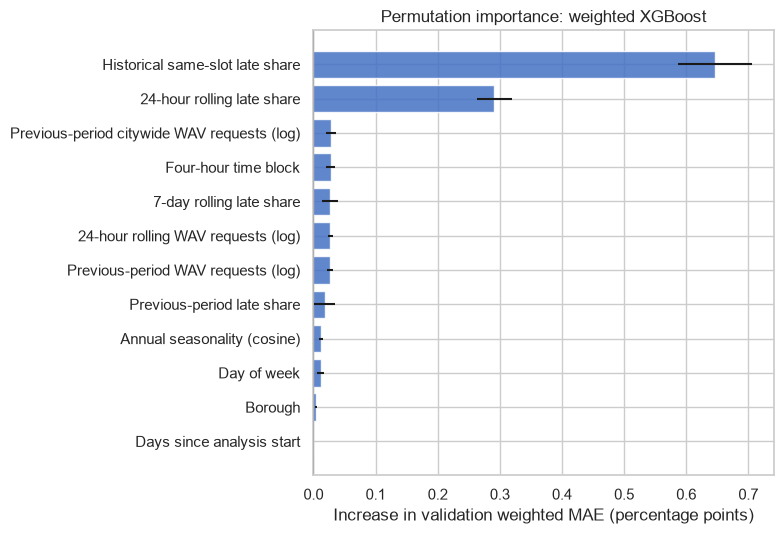

In [539]:
PERMUTATION_FEATURE_DISPLAY_NAMES = {
    "historical_same_slot_late_share": (
        "Historical same-slot late share"
    ),
    "rolling_24h_late_share": "24-hour rolling late share",
    "log1p_lag_1_citywide_wav_request_count": (
        "Previous-period citywide WAV requests (log)"
    ),
    "time_block": "Four-hour time block",
    "rolling_7d_late_share": "7-day rolling late share",
    "log1p_rolling_24h_wav_request_count": (
        "24-hour rolling WAV requests (log)"
    ),
    "log1p_lag_1_wav_request_count": (
        "Previous-period WAV requests (log)"
    ),
    "lag_1_late_share": "Previous-period late share",
    "day_of_year_cos": "Annual seasonality (cosine)",
    "day_of_week": "Day of week",
    "borough": "Borough",
    "days_since_analysis_start": "Days since analysis start",
}

importance_plot_data = (
    xgb_permutation_importance_df.head(12)
    .sort_values("importance_mean_percentage_points")
)
importance_plot_data["feature_display_name"] = (
    importance_plot_data["feature_name"]
    .map(PERMUTATION_FEATURE_DISPLAY_NAMES)
    .fillna(
        importance_plot_data["feature_name"]
        .str.replace("_", " ", regex=False)
        .str.capitalize()
    )
)

figure, axis = plt.subplots(figsize=(8, 5.5))
axis.barh(
    importance_plot_data["feature_display_name"],
    importance_plot_data["importance_mean_percentage_points"],
    xerr=importance_plot_data[
        "importance_standard_deviation_percentage_points"
    ],
    color="#4472C4",
    alpha=0.85,
)
axis.axvline(0, color="black", linewidth=0.8)
axis.set_xlabel(
    "Increase in validation weighted MAE (percentage points)"
)
axis.set_ylabel("")
axis.set_title("Permutation importance: weighted XGBoost")
figure.tight_layout()
figure.savefig(
    FIGURE_OUTPUT_ROOT / "wav_permutation_importance.png",
    dpi=300,
    bbox_inches="tight",
)
figure.savefig(
    FIGURE_OUTPUT_ROOT / "wav_permutation_importance.pdf",
    bbox_inches="tight",
)
plt.show()

In [540]:
selected_glm_validation_metrics = calculate_forecast_metrics(
    selected_glm_validation_scoring_df,
    selected_glm_prediction_column,
    f"Grouped Binomial GLM ({selected_glm_specification})",
)
selected_xgb_validation_metrics = calculate_forecast_metrics(
    selected_xgb_validation_scoring_df,
    selected_xgb_prediction_column,
    f"Weighted XGBoost ({selected_xgb_candidate_name})",
)
validation_model_comparison_df = pd.concat(
    [
        validation_benchmark_metrics_df,
        pd.DataFrame(
            [
                selected_glm_validation_metrics,
                selected_xgb_validation_metrics,
            ]
        ),
    ],
    ignore_index=True,
).sort_values(PRIMARY_SELECTION_METRIC)

validation_model_comparison_df[
    [
        "model_name",
        "weighted_mae_percentage_points",
        "weighted_rmse_percentage_points",
        "unweighted_mae_percentage_points",
        "calibration_gap_percentage_points",
    ]
]

,model_name,weighted_mae_percentage_points,weighted_rmse_percentage_points,unweighted_mae_percentage_points,calibration_gap_percentage_points
2,Weighted XGBoost (core_regularised),2.5030,3.6514,4.9201,-0.6051
1,Grouped Binomial GLM (core),2.5917,3.7854,4.7880,-1.0181
0,24-hour persistence,2.8963,4.2343,5.3726,-0.0182


In [541]:
selected_glm_validation_forecasts_df = (
    selected_glm_validation_scoring_df[
        [*MODEL_KEY_COLUMNS, selected_glm_prediction_column]
    ]
    .rename(
        columns={
            selected_glm_prediction_column: (
                "grouped_binomial_glm_prediction"
            )
        }
    )
)
selected_xgb_validation_forecasts_df = (
    selected_xgb_validation_scoring_df[
        [*MODEL_KEY_COLUMNS, selected_xgb_prediction_column]
    ]
    .rename(
        columns={
            selected_xgb_prediction_column: (
                "weighted_xgboost_prediction"
            )
        }
    )
)
validation_model_forecasts_df = (
    selected_glm_validation_forecasts_df.merge(
        selected_xgb_validation_forecasts_df,
        on=list(MODEL_KEY_COLUMNS),
        how="inner",
        validate="one_to_one",
    )
)
future_model_forecasts_df = glm_future_forecasts_df.merge(
    xgb_future_forecasts_df,
    on=list(MODEL_KEY_COLUMNS),
    how="inner",
    validate="one_to_one",
)
model_forecasts_df = pd.concat(
    [validation_model_forecasts_df, future_model_forecasts_df],
    ignore_index=True,
).sort_values(["period_start", "borough"])

model_prediction_columns = (
    "grouped_binomial_glm_prediction",
    "weighted_xgboost_prediction",
)
if set(MODEL_TARGET_COLUMNS).intersection(model_forecasts_df.columns):
    raise RuntimeError("Model forecasts contain protected targets.")
if model_forecasts_df.duplicated(list(MODEL_KEY_COLUMNS)).any():
    raise RuntimeError("Model forecast keys are not unique.")
if model_forecasts_df[list(model_prediction_columns)].isna().any().any():
    raise RuntimeError("Model forecasts contain missing values.")

# 9. Future-test evaluation and robustness

Evaluate frozen November-December forecasts, calibration, subgroup errors, high-risk selection, and temporal robustness.

## 9.1 Future-test performance and calibration

Join frozen forecasts to November-December outcomes and score persistence, GLM, and XGBoost on the same observed borough-periods.

In [542]:
test_panel_mask = saved_curated_wav_panel_df["split_label"].eq(
    "test"
)
test_scoreable_mask = (
    test_panel_mask
    & saved_curated_wav_panel_df["target_observed"]
)
test_outcome_columns = (
    *MODEL_KEY_COLUMNS,
    *MODEL_TARGET_COLUMNS,
    "time_block",
    "is_holiday",
    "rolling_24h_wav_request_count",
)
test_outcomes_df = saved_curated_wav_panel_df.loc[
    test_scoreable_mask,
    test_outcome_columns,
].copy()

pd.DataFrame(
    [
        {
            "complete_test_grid_rows": int(test_panel_mask.sum()),
            "scoreable_test_rows": len(test_outcomes_df),
            "completed_wav_requests": int(
                test_outcomes_df["wav_request_count"].sum()
            ),
        }
    ]
)

,complete_test_grid_rows,scoreable_test_rows,completed_wav_requests
0,1830,1731,114672


In [543]:
test_benchmark_forecasts_df = benchmark_forecasts_df.loc[
    benchmark_forecasts_df["split_label"].eq("test")
]
test_model_forecasts_df = model_forecasts_df.loc[
    model_forecasts_df["split_label"].eq("test")
]

test_scoring_df = (
    test_outcomes_df
    .merge(
        test_benchmark_forecasts_df,
        on=list(MODEL_KEY_COLUMNS),
        how="left",
        validate="one_to_one",
    )
    .merge(
        test_model_forecasts_df,
        on=list(MODEL_KEY_COLUMNS),
        how="left",
        validate="one_to_one",
    )
)
if len(test_scoring_df) != len(test_outcomes_df):
    raise RuntimeError("Test forecast merge changed the scoreable row count.")
if test_scoring_df[list(model_prediction_columns)].isna().any().any():
    raise RuntimeError("Test model forecasts are missing.")
if test_scoring_df[
    list(BENCHMARK_PREDICTION_COLUMNS.values())
].isna().any().any():
    raise RuntimeError("Test benchmark forecasts are missing.")

TEST_MODEL_PREDICTION_COLUMNS = {
    **BENCHMARK_PREDICTION_COLUMNS,
    f"Grouped Binomial GLM ({selected_glm_specification})": (
        "grouped_binomial_glm_prediction"
    ),
    f"Weighted XGBoost ({selected_xgb_candidate_name})": (
        "weighted_xgboost_prediction"
    ),
}
SELECTED_XGB_MODEL_NAME = (
    f"Weighted XGBoost ({selected_xgb_candidate_name})"
)
SELECTED_XGB_PREDICTION_COLUMN = (
    TEST_MODEL_PREDICTION_COLUMNS[SELECTED_XGB_MODEL_NAME]
)

print(
    "The frozen November-December forecasts have now been scored "
    "exactly once in this run."
)

The frozen November-December forecasts have now been scored exactly once in this run.


In [544]:
test_model_metric_records = []

for model_name, prediction_column in (
    TEST_MODEL_PREDICTION_COLUMNS.items()
):
    test_model_metric_records.append(
        calculate_forecast_metrics(
            test_scoring_df,
            prediction_column,
            model_name,
        )
    )

test_model_comparison_df = (
    pd.DataFrame(test_model_metric_records)
    .sort_values(PRIMARY_SELECTION_METRIC)
    .reset_index(drop=True)
)
test_model_comparison_df.to_csv(
    TABLE_OUTPUT_ROOT / "wav_model_comparison.csv",
    index=False,
)
test_model_comparison_df[
    [
        "model_name",
        "weighted_mae_percentage_points",
        "weighted_rmse_percentage_points",
        "unweighted_mae_percentage_points",
        "observed_weighted_late_share",
        "predicted_weighted_late_share",
        "calibration_gap_percentage_points",
    ]
]

,model_name,weighted_mae_percentage_points,weighted_rmse_percentage_points,unweighted_mae_percentage_points,observed_weighted_late_share,predicted_weighted_late_share,calibration_gap_percentage_points
0,Weighted XGBoost (core_regularised),2.5400,3.6140,5.2293,0.0617,0.0669,0.5170
1,Grouped Binomial GLM (core),2.7171,3.8454,5.3114,0.0617,0.0688,0.7104
2,24-hour persistence,2.8916,4.0874,5.5265,0.0617,0.0616,-0.0098


In [545]:
test_scoring_df["request_volume_band"] = pd.cut(
    test_scoring_df["wav_request_count"],
    bins=REQUEST_VOLUME_BIN_EDGES,
    labels=REQUEST_VOLUME_BIN_LABELS,
)

# Expected demand uses only earlier matching borough-calendar periods.
historical_demand_source_df = (
    saved_curated_wav_panel_df[
        [
            *MODEL_KEY_COLUMNS,
            "time_block",
            "day_of_week_number",
            "wav_request_count",
        ]
    ]
    .sort_values(["period_start", "borough"])
    .copy()
)
same_slot_demand_groups = historical_demand_source_df.groupby(
    ["borough", "day_of_week_number", "time_block"],
    sort=False,
)["wav_request_count"]
same_slot_history_count = same_slot_demand_groups.cumcount()
same_slot_history_request_sum = (
    same_slot_demand_groups.cumsum()
    - historical_demand_source_df["wav_request_count"]
)
historical_demand_source_df["expected_request_count"] = (
    same_slot_history_request_sum
    / same_slot_history_count.where(same_slot_history_count.gt(0))
)
test_scoring_df = test_scoring_df.merge(
    historical_demand_source_df[
        [*MODEL_KEY_COLUMNS, "expected_request_count"]
    ],
    on=list(MODEL_KEY_COLUMNS),
    how="left",
    validate="one_to_one",
)
if test_scoring_df["expected_request_count"].isna().any():
    raise RuntimeError("Expected-demand proxy is missing in the test set.")

In [546]:
def calculate_metrics_by_group(
    evaluation_data: pd.DataFrame,
    prediction_columns: dict[str, str],
    grouping_column: str,
) -> pd.DataFrame:
    """
    Calculate the frozen forecast metrics for every level of one group.

    Args:
        evaluation_data: Scoreable rows with targets and predictions.
        prediction_columns: Mapping from model labels to forecast columns.
        grouping_column: Column defining the evaluation subgroups.

    Returns:
        Long-form model metrics for every observed subgroup.
    """
    grouped_metric_records = []
    for model_name, prediction_column in prediction_columns.items():
        for group_value, group_data in evaluation_data.groupby(
            grouping_column,
            observed=True,
        ):
            metric_record = calculate_forecast_metrics(
                group_data,
                prediction_column,
                model_name,
                evaluation_group=str(group_value),
            )
            metric_record["evaluation_dimension"] = grouping_column
            grouped_metric_records.append(metric_record)

    return pd.DataFrame(grouped_metric_records)

In [547]:
selected_xgb_prediction_mapping = {
    SELECTED_XGB_MODEL_NAME: (
        SELECTED_XGB_PREDICTION_COLUMN
    )
}
test_borough_performance_df = calculate_metrics_by_group(
    test_scoring_df,
    selected_xgb_prediction_mapping,
    "borough",
)
test_volume_performance_df = calculate_metrics_by_group(
    test_scoring_df,
    selected_xgb_prediction_mapping,
    "request_volume_band",
)
test_group_performance_df = pd.concat(
    [test_borough_performance_df, test_volume_performance_df],
    ignore_index=True,
)
test_group_performance_df.to_csv(
    TABLE_OUTPUT_ROOT / "wav_group_performance.csv",
    index=False,
)
test_group_performance_df[
    [
        "evaluation_dimension",
        "evaluation_group",
        "wav_request_count",
        "weighted_mae_percentage_points",
        "unweighted_mae_percentage_points",
    ]
]

,evaluation_dimension,evaluation_group,wav_request_count,weighted_mae_percentage_points,unweighted_mae_percentage_points
0,borough,Bronx,17157,3.0043,4.6284
1,borough,Brooklyn,34055,1.9638,2.6970
2,borough,Manhattan,42209,2.1868,2.8598
3,borough,Queens,19503,3.1982,4.6561
4,borough,Staten Island,1748,10.3953,13.5245
5,request_volume_band,1-10 requests,1851,9.8411,12.0800
6,request_volume_band,11-50 requests,15513,4.3283,4.7880
7,request_volume_band,51-100 requests,23415,2.8647,2.8905
8,request_volume_band,More than 100 requests,73893,1.8789,1.9692


In [548]:
test_calibration_df = pd.concat(
    [
        build_weighted_calibration_table(
            test_scoring_df,
            prediction_column,
            model_name,
        )
        for model_name, prediction_column in (
            TEST_MODEL_PREDICTION_COLUMNS.items()
        )
    ],
    ignore_index=True,
)

In [549]:
def calculate_high_risk_performance(
    evaluation_data: pd.DataFrame,
    prediction_column: str,
    model_name: str,
    selection_mask: pd.Series,
    selection_rule: str,
) -> dict[str, float | int | str]:
    """
    Evaluate how a forecast selection captures high-risk periods.

    Args:
        evaluation_data: Scoreable rows with risk and demand support.
        prediction_column: Column containing predicted late shares.
        model_name: Model label for the output record.
        selection_mask: Boolean rows selected for operational attention.
        selection_rule: Description of the forecast selection rule.

    Returns:
        Precision, recall, demand-weighted capture, and support statistics.
    """
    selected_rows = selection_mask.astype(bool)
    observed_high_risk = evaluation_data["late_share"].gt(
        HIGH_RISK_THRESHOLD
    )
    true_positive = selected_rows & observed_high_risk
    request_weights = evaluation_data["wav_request_count"]

    selected_count = int(selected_rows.sum())
    high_risk_count = int(observed_high_risk.sum())
    selected_weight = float(request_weights.loc[selected_rows].sum())
    high_risk_weight = float(
        request_weights.loc[observed_high_risk].sum()
    )
    total_request_weight = float(request_weights.sum())
    total_late_trip_count = float(
        evaluation_data["late_trip_count"].sum()
    )

    precision = (
        true_positive.sum() / selected_count
        if selected_count
        else np.nan
    )
    recall = (
        true_positive.sum() / high_risk_count
        if high_risk_count
        else np.nan
    )
    weighted_precision = (
        request_weights.loc[true_positive].sum() / selected_weight
        if selected_weight
        else np.nan
    )
    weighted_recall = (
        request_weights.loc[true_positive].sum() / high_risk_weight
        if high_risk_weight
        else np.nan
    )

    return {
        "model_name": model_name,
        "selection_rule": selection_rule,
        "selected_period_count": selected_count,
        "observed_high_risk_period_count": high_risk_count,
        "true_positive_period_count": int(true_positive.sum()),
        "precision": precision,
        "recall": recall,
        "demand_weighted_precision": weighted_precision,
        "demand_weighted_recall": weighted_recall,
        "selected_request_share": (
            selected_weight / total_request_weight
            if total_request_weight
            else np.nan
        ),
        "late_trip_capture_rate": (
            evaluation_data.loc[
                selected_rows,
                "late_trip_count",
            ].sum()
            / total_late_trip_count
            if total_late_trip_count
            else np.nan
        ),
        "median_expected_request_count": (
            evaluation_data.loc[
                selected_rows,
                "expected_request_count",
            ].median()
            if selected_count
            else np.nan
        ),
        "share_selected_with_expected_demand_at_least_10": (
            evaluation_data.loc[
                selected_rows,
                "expected_request_count",
            ].ge(10).mean()
            if selected_count
            else np.nan
        ),
    }

In [550]:
predicted_threshold_mask = test_scoring_df[
    SELECTED_XGB_PREDICTION_COLUMN
].gt(HIGH_RISK_THRESHOLD)
threshold_performance = calculate_high_risk_performance(
    test_scoring_df,
    SELECTED_XGB_PREDICTION_COLUMN,
    SELECTED_XGB_MODEL_NAME,
    predicted_threshold_mask,
    f"Predicted risk > {HIGH_RISK_THRESHOLD:.0%}",
)

test_scoring_df["operational_priority_score"] = (
    test_scoring_df[SELECTED_XGB_PREDICTION_COLUMN]
    * test_scoring_df["expected_request_count"]
)
priority_ranks = test_scoring_df["operational_priority_score"].rank(
    method="first",
    ascending=False,
)
priority_selected_count = int(
    np.ceil(len(test_scoring_df) * TOP_RISK_CAPTURE_SHARE)
)
priority_mask = priority_ranks.le(priority_selected_count)
priority_performance = calculate_high_risk_performance(
    test_scoring_df,
    SELECTED_XGB_PREDICTION_COLUMN,
    SELECTED_XGB_MODEL_NAME,
    priority_mask,
    (
        f"Top {TOP_RISK_CAPTURE_SHARE:.0%} by predicted risk "
        "x historical expected demand"
    ),
)

high_risk_performance_df = pd.DataFrame(
    [threshold_performance, priority_performance]
)
high_risk_performance_df.to_csv(
    TABLE_OUTPUT_ROOT / "wav_high_risk_performance.csv",
    index=False,
)
high_risk_performance_df[
    [
        "selection_rule",
        "selected_period_count",
        "precision",
        "recall",
        "selected_request_share",
        "late_trip_capture_rate",
    ]
]

,selection_rule,selected_period_count,precision,recall,selected_request_share,late_trip_capture_rate
0,Predicted risk > 10%,373,0.4263,0.4251,0.0991,0.1826
1,Top 10% by predicted risk x historical expecte...,174,0.2241,0.1043,0.3128,0.3612


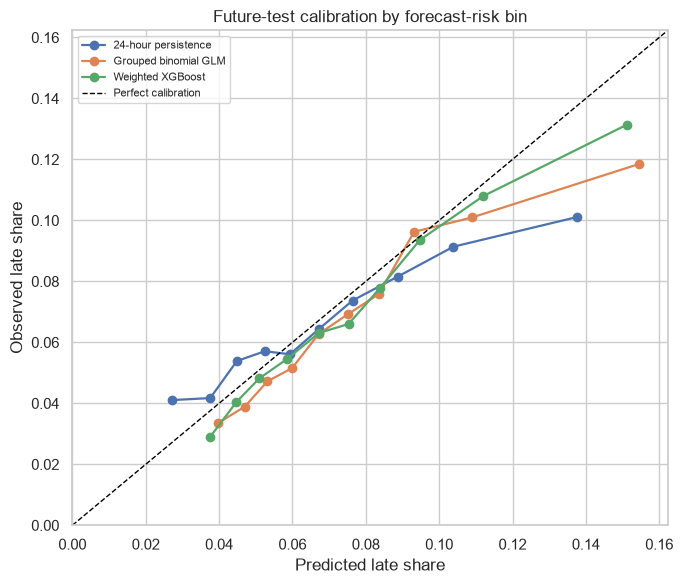

In [551]:
MODEL_DISPLAY_NAMES = {
    f"Grouped Binomial GLM ({selected_glm_specification})": (
        "Grouped binomial GLM"
    ),
    f"Weighted XGBoost ({selected_xgb_candidate_name})": (
        "Weighted XGBoost"
    ),
}

figure, axis = plt.subplots(figsize=(7, 6))

for model_name, calibration_data in test_calibration_df.groupby(
    "model_name"
):
    axis.plot(
        calibration_data["predicted_late_share"],
        calibration_data["observed_late_share"],
        marker="o",
        linewidth=1.6,
        label=MODEL_DISPLAY_NAMES.get(model_name, model_name),
    )

test_calibration_limit = 1.05 * max(
    test_calibration_df[
        ["predicted_late_share", "observed_late_share"]
    ].max()
)
axis.plot(
    [0, test_calibration_limit],
    [0, test_calibration_limit],
    linestyle="--",
    color="black",
    linewidth=1,
    label="Perfect calibration",
)
axis.set_xlim(0, test_calibration_limit)
axis.set_ylim(0, test_calibration_limit)
axis.set_xlabel("Predicted late share")
axis.set_ylabel("Observed late share")
axis.set_title("Future-test calibration by forecast-risk bin")
axis.legend(fontsize=8)
figure.tight_layout()
save_report_figure(figure, "wav_model_calibration")
plt.show()

## 9.2 Focused robustness checks

Evaluate low-support sensitivity and compare XGBoost with persistence across expanding monthly backtests.

In [552]:
def fit_fixed_xgboost_forecast(
    fitting_data: pd.DataFrame,
    prediction_data: pd.DataFrame,
    categorical_features: tuple[str, ...],
    numeric_features: tuple[str, ...],
) -> np.ndarray:
    """
    Fit the selected XGBoost configuration and forecast a later period.

    Args:
        fitting_data: Earlier scoreable rows with targets and predictors.
        prediction_data: Later rows containing forecast predictors.
        categorical_features: Frozen categorical predictors.
        numeric_features: Frozen numerical predictors.

    Returns:
        Bounded late-share forecasts for prediction_data.
    """
    predictor_columns = (*categorical_features, *numeric_features)
    preprocessor = build_model_preprocessor(
        categorical_features,
        numeric_features,
        standardise_numeric=False,
        drop_first_category=False,
    )
    fitting_matrix = preprocessor.fit_transform(
        fitting_data.loc[:, predictor_columns]
    )
    prediction_matrix = preprocessor.transform(
        prediction_data.loc[:, predictor_columns]
    )

    scenario_model = build_xgboost_model(
        configuration=selected_xgb_configuration,
        n_estimators=selected_xgb_tree_count,
    )
    scenario_model.fit(
        fitting_matrix,
        fitting_data["late_share"],
        sample_weight=fitting_data["wav_request_count"],
        verbose=False,
    )
    predictions = scenario_model.predict(prediction_matrix)
    if not (
        np.isfinite(predictions).all()
        and (predictions >= 0).all()
        and (predictions <= 1).all()
    ):
        raise ValueError("Fixed XGBoost forecast produced invalid values.")
    return predictions

In [553]:
low_support_metric_records = []

for scope_name, scope_mask in {
    "All five boroughs": pd.Series(True, index=test_scoring_df.index),
    "Exclude Staten Island": test_scoring_df["borough"].ne(
        "Staten Island"
    ),
}.items():
    low_support_metric_records.append(
        calculate_forecast_metrics(
            test_scoring_df.loc[scope_mask],
            SELECTED_XGB_PREDICTION_COLUMN,
            SELECTED_XGB_MODEL_NAME,
            evaluation_group=scope_name,
        )
    )

low_support_summary_df = pd.DataFrame(low_support_metric_records)
low_support_summary_df[
    [
        "evaluation_group",
        "wav_request_count",
        "weighted_mae_percentage_points",
        "unweighted_mae_percentage_points",
    ]
]

,evaluation_group,wav_request_count,weighted_mae_percentage_points,unweighted_mae_percentage_points
0,All five boroughs,114672,2.5400,5.2293
1,Exclude Staten Island,112924,2.4184,3.7097


In [554]:
EXPANDING_BACKTEST_FOLDS = (
    (
        "July 2025",
        pd.Timestamp("2025-07-01"),
        pd.Timestamp("2025-08-01"),
    ),
    (
        "August 2025",
        pd.Timestamp("2025-08-01"),
        pd.Timestamp("2025-09-01"),
    ),
    (
        "September 2025",
        pd.Timestamp("2025-09-01"),
        pd.Timestamp("2025-10-01"),
    ),
    (
        "October 2025",
        pd.Timestamp("2025-10-01"),
        pd.Timestamp("2025-11-01"),
    ),
)

if any(
    evaluation_end > pd.Timestamp(VALIDATION_END_EXCLUSIVE)
    for _, _, evaluation_end in EXPANDING_BACKTEST_FOLDS
):
    raise RuntimeError("A robustness backtest enters the future test.")

In [555]:
backtest_metric_records = []
backtest_source_df = add_borough_time_block(
    saved_curated_wav_panel_df.loc[
        saved_curated_wav_panel_df["split_label"].isin(
            ["training", "validation"]
        )
        & saved_curated_wav_panel_df["target_observed"]
    ].copy()
)

# Expand the training window while holding out one later month per fold.
for fold_name, evaluation_start, evaluation_end in (
    EXPANDING_BACKTEST_FOLDS
):
    backtest_training_df = backtest_source_df.loc[
        backtest_source_df["period_start"] < evaluation_start
    ].copy()
    backtest_evaluation_df = backtest_source_df.loc[
        backtest_source_df["period_start"].between(
            evaluation_start,
            evaluation_end,
            inclusive="left",
        )
    ].copy()

    # Generate forecasts using only information available before the fold.
    training_borough_risk = (
        backtest_training_df
        .groupby("borough")
        .apply(
            lambda data: (
                data["late_trip_count"].sum()
                / data["wav_request_count"].sum()
            ),
            include_groups=False,
        )
    )
    training_global_risk = (
        backtest_training_df["late_trip_count"].sum()
        / backtest_training_df["wav_request_count"].sum()
    )
    persistence_predictions = (
        backtest_evaluation_df["rolling_24h_late_share"]
        .fillna(
            backtest_evaluation_df["borough"].map(
                training_borough_risk
            )
        )
        .fillna(training_global_risk)
    )
    backtest_xgb_predictions = fit_fixed_xgboost_forecast(
        backtest_training_df,
        backtest_evaluation_df,
        selected_xgb_features["categorical_features"],
        selected_xgb_features["numeric_features"],
    )

    fold_scoring_df = backtest_evaluation_df[
        [*MODEL_KEY_COLUMNS, *MODEL_TARGET_COLUMNS]
    ].copy()
    fold_scoring_df["backtest_persistence_prediction"] = (
        persistence_predictions.to_numpy()
    )
    fold_scoring_df["backtest_xgboost_prediction"] = (
        backtest_xgb_predictions
    )

    # Score one result record per model and evaluation fold.
    for model_name, prediction_column in {
        "24-hour persistence": "backtest_persistence_prediction",
        SELECTED_XGB_MODEL_NAME: (
            "backtest_xgboost_prediction"
        ),
    }.items():
        metric_record = calculate_forecast_metrics(
            fold_scoring_df,
            prediction_column,
            model_name,
            evaluation_group=fold_name,
        )
        metric_record.update(
            {
                "fold_name": fold_name,
                "training_end_exclusive": evaluation_start,
                "evaluation_end_exclusive": evaluation_end,
                "training_row_count": len(backtest_training_df),
            }
        )
        backtest_metric_records.append(metric_record)

expanding_backtest_metrics_df = pd.DataFrame(
    backtest_metric_records
)
expanding_backtest_metrics_df.to_csv(
    TABLE_OUTPUT_ROOT / "wav_expanding_backtest_metrics.csv",
    index=False,
)
expanding_backtest_metrics_df.pivot(
    index="fold_name",
    columns="model_name",
    values="weighted_mae_percentage_points",
)

model_name,24-hour persistence,Weighted XGBoost (core_regularised)
fold_name,,
August 2025,3.4619,5.3246
July 2025,4.1213,4.0152
October 2025,2.6855,2.2957
September 2025,3.1142,2.7629
